# 5.0 · EDA JobPath

**CRISP-DM fase 2 · Data Understanding**  
**Proyecto:** JobPath · patrones de transición ocupacional  
**Cuaderno único de análisis exploratorio**

---

## Ficha de la sesión

| Elemento | Detalle |
|---|---|
| Cuaderno | `notebooks/refactor/5.0_EDA_jobpath.ipynb` |
| Lógica pesada | `scripts/ScriptsCsv/EDA/` (módulos importados, no copiados) |
| Insumos | `data/03_processed/` (versiones A y B) y `data/04_transformed/` (X, y, transformadores) |
| Salidas | `reports/eda_jobpath/figures/` (28 figuras aprobadas) y `reports/eda_jobpath/tables/split_map_resume_id.csv` |
| Semilla | 42 |
| Ejecución | `Run All`, rutas relativas, sin interacción manual |
| Privacidad | Resultados agregados; `resume_id` solo se usa como clave de agrupación |

Este cuaderno **no vuelve a limpiar, winsorizar, escalar ni dividir** los datos. Resume y audita lo que ya hicieron los cuadernos 2.0 y 3.0, y explora el universo resultante. Las únicas escrituras son las figuras aprobadas y el mapa de partición por persona.

## Cómo se lee este cuaderno

Cada caja de código va precedida por una explicación en español con cuatro apartados:

1. **¿Qué hace?** La operación concreta que ejecuta.
2. **¿Por qué existe?** La pregunta de negocio o de calidad que responde.
3. **¿Qué recibe y qué entrega?** Entradas, tablas y figuras.
4. **Papel en el proyecto.** Qué sección del informe alimenta y qué le deja a la fase 4.

Después de cada resultado hay una lectura en lenguaje de negocio. **Todas las cifras citadas salen de celdas ejecutadas**; el texto explicativo no inventa números ni los escribe a mano.

Cada figura declara su fuente exacta en dos lugares: en el pie del PNG y en el markdown que la precede. La etiqueta **A** significa `empleos_limpio_con_competencias.csv` (con outliers) y **B** significa `empleos_limpio_con_competencias_sin_outliers.csv` (sin outliers, IQR).


## 0. Encuadre metodológico y tensiones del encargo

### 0.1 Una iteración válida de la fase 2

El orden real de ejecución del proyecto fue:

`1.0 comprensión del negocio → 2.0 preprocesamiento → 3.0 transformación → 4.0 / 4.1 PCA → 5.0 EDA`

La fase 2 de CRISP-DM (*Data Understanding*) se ejecuta aquí de forma **formal y trazable**, después de la fase 3. No es un retroceso: es una iteración consciente. La preparación dejó decisiones y señales —nulos estructurales, winsorización, colinealidad, fuga del target— que merecen un análisis exploratorio propio antes de modelar. El número `5.0` del archivo es una secuencia de cuaderno, no la fase 5 del método (Evaluación).

### 0.2 Charter frente a target: una tensión que se documenta

La pregunta del charter es amplia: **qué transiciones ocupacionales se repiten y qué papel juega la formación de la persona**. El target disponible, `reincide`, es una variable binaria por experiencia: vale 1 cuando la persona ya había tenido ese mismo oficio. Es un proxy útil, pero **no es la pregunta completa**:

- No dice *hacia dónde* cambia la persona, solo *si repite*.
- No distingue una promoción, un cambio de área o un retorno forzado.
- No incorpora el campo de estudio, porque ese dato no existe en la fuente.

Por eso el EDA describe transiciones, permanencia y retornos por separado, y trata el target como una etiqueta supervisada que se estudiará en la fase 4. La brecha entre charter y target queda declarada como límite, no disimulada.

### 0.3 "Qué estudió" no está disponible

La fuente **no contiene el programa ni el campo de estudio**. Lo que existe es:

| Variable | Qué mide realmente | Uso en este EDA |
|---|---|---|
| `university_level` | Nivel educativo declarado (secundaria, grado, máster, doctorado) | Aproximación parcial al nivel, no al campo |
| `isco_group` / `isco_group_label` | Área ocupacional agregada | Aproximación parcial al sector, no a la titulación |
| Perfil de competencias (`n_skills_*`, listas ESCO) | Demandas del oficio | Aproximación parcial al contenido del trabajo |

Ninguna de las tres responde "qué estudió". Se usan como proxies y así se declara en el informe. `matched_code` es un código de ocupación, no un código de titulación.

### 0.4 Fuga y circularidad

`reincide` se define como `veces_ese_oficio > 1`. Esa columna también está en `X`, junto con sus versiones `veces_ese_oficio_bin` y `veces_ese_oficio_rob`. Por tanto:

- **Fuga directa:** usar cualquiera de esas columnas como feature reproduce el target.
- **Circularidad a nivel persona:** `n_returns >= 1` equivale a que la persona tenga al menos un oficio repetido. No es una variable independiente.
- **Familias redundantes:** `dur_q`, `dur_total`, `span_q`; `n_skills_essential`, `n_skills_competence`, `n_skills_knowledge`; `n_jobs`, `n_occ`.

El EDA excluye `veces_ese_oficio*` de todo cruce con el target y marca la fuga como **riesgo bloqueante** para la fase 4. `n_returns` se usa solo como descriptor.

### 0.5 Versiones A y B

| Versión | Archivo | Diferencia |
|---|---|---|
| **A** | `empleos_limpio_con_competencias.csv` | Datos limpios, con outliers |
| **B** | `empleos_limpio_con_competencias_sin_outliers.csv` | Winsorización IQR en cuatro columnas de competencias y repetición |

La duración (`dur_q`) **no** se winsoriza en B. Por eso se añade un diagnóstico hipotético de recorte, solo en RAM, para decidir si valdría la pena volver al 2.0.

### 0.6 PCA: se reutiliza, no se rehace

El EDA no ajusta un PCA nuevo. Reutiliza las salidas guardadas de `4.0_PCA.ipynb` (muestra de 10 k) y `4.1_PCA_completo.ipynb` (muestra de 50 k) y las muestra juntas como prueba de estabilidad. Límite declarado: ese PCA cubre las variables numéricas escaladas del bloque de transformación, **no las 2.839 columnas de `X`**; un PCA sobre dummies no es una buena práctica y no se realiza.

### 0.7 Segmento derivado sin mirar el target

Se construye un segmento de trayectoria con umbrales observados (Q75 de autolazo, exploración y retorno no adyacente) sobre personas con al menos dos empleos. El segmento se valida contra nivel educativo e ISCO, **nunca contra `reincide`**, porque compartiría la definición de retorno.

## 1. Preparación del entorno

**¿Qué hace?** Importa todas las librerías en la primera caja, resuelve la raíz del proyecto, registra la versión del entorno y construye la configuración compartida.

**¿Por qué existe?** El cuaderno debe ejecutarse completo con `Run All` desde `notebooks/refactor`, sin rutas absolutas ni estado oculto. La raíz se busca subiendo directorios hasta encontrar `data/` y `notebooks/`.

**¿Qué recibe y qué entrega?** No recibe datos. Entrega `ROOT`, `CONFIG`, la semilla fija y las rutas de figuras y tablas.

**Papel en el proyecto.** Es la puerta de entrada reproducible: cualquier persona que clone el repositorio puede ejecutar el cuaderno sin editar rutas.

In [1]:
import platform
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


def find_project_root(start: Path) -> Path:
    """Walk upwards until the directory that contains data and notebooks."""
    current = start.resolve()
    for candidate in (current, *current.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    return current


ROOT = find_project_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.EDA import EDAPipeline, default_config
from scripts.ScriptsCsv.EDA.config import VERSION_LABELS, VERSIONS

CONFIG = default_config(ROOT)

environment = pd.DataFrame(
    [
        {"elemento": "Python", "valor": platform.python_version()},
        {"elemento": "pandas", "valor": pd.__version__},
        {"elemento": "numpy", "valor": np.__version__},
        {"elemento": "matplotlib", "valor": matplotlib.__version__},
        {"elemento": "seaborn", "valor": sns.__version__},
        {"elemento": "raíz del proyecto", "valor": str(ROOT)},
        {"elemento": "figuras", "valor": str(CONFIG.figures_dir)},
        {"elemento": "tablas", "valor": str(CONFIG.tables_dir)},
        {"elemento": "semilla", "valor": str(CONFIG.seed)},
    ]
)
display(environment)

,elemento,valor
0,Python,3.12.10
1,pandas,3.0.6
2,numpy,2.5.4
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,raíz del proyecto,C:\Users\User\Documents\JobPath\MineriaProtect
6,figuras,C:\Users\User\Documents\JobPath\MineriaProtect\reports\eda_jobpath\figures
7,tablas,C:\Users\User\Documents\JobPath\MineriaProtect\reports\eda_jobpath\tables
8,semilla,42


**Lectura.** El entorno queda fijado y visible. La raíz se resolvió sin escribir una ruta absoluta en el código, y las carpetas de salida se crean al guardar la primera figura. La semilla es la misma que usó la transformación, lo que permite reproducir el split sin discrepancias.

## 2. Carga, inventario y huella de los insumos

**¿Qué hace?** Construye el pipeline con inyección de dependencias, toma una huella SHA-256 de todos los insumos y carga en memoria las versiones A y B, además de `y_train`/`y_test`.

**¿Por qué existe?** Antes de analizar hay que demostrar que los insumos no se modifican y que el universo cargado es el esperado. La huella se compara al final del cuaderno.

**¿Qué recibe y qué entrega?** Recibe las rutas de `data/`. Entrega los DataFrames en memoria, el inventario de archivos y la huella inicial.

**Papel en el proyecto.** Es el control de integridad que exige la rúbrica y la base de la reproducibilidad.

In [2]:
pipeline = EDAPipeline.default(CONFIG)
pipeline.start()

inventory_rows = []
for version in VERSIONS:
    clean_path = CONFIG.clean_paths[version]
    inventory_rows.append(
        {
            "version": VERSION_LABELS[version],
            "archivo": clean_path.name,
            "tamano_mb": pipeline.loader.file_size_mb(clean_path),
            "filas": len(pipeline.frames[version]),
            "columnas": pipeline.frames[version].shape[1],
        }
    )
for version in VERSIONS:
    for split in ("train", "test"):
        y_path = CONFIG.transformed_dir / version / split / f"y_{split}.csv"
        inventory_rows.append(
            {
                "version": VERSION_LABELS[version],
                "archivo": f"{version}/{split}/y_{split}.csv",
                "tamano_mb": pipeline.loader.file_size_mb(y_path),
                "filas": len(pipeline.y[version][split]),
                "columnas": pipeline.y[version][split].shape[1],
            }
        )
display(pd.DataFrame(inventory_rows))

for version in VERSIONS:
    frame = pipeline.frames[version]
    print(
        f"{VERSION_LABELS[version]}: {len(frame):,} experiencias, "
        f"{frame['resume_id'].nunique():,} personas, "
        f"{frame['occupation_code'].notna().sum():,} experiencias con oficio clasificado."
    )

,version,archivo,tamano_mb,filas,columnas
0,A · con outliers,empleos_limpio_con_competencias.csv,274.470,376567,25
1,B · sin outliers (IQR),empleos_limpio_con_competencias_sin_outliers.csv,275.810,376567,25
2,A · con outliers,con_outliers/train/y_train.csv,0.800,278987,1
3,A · con outliers,con_outliers/test/y_test.csv,0.200,69276,1
4,B · sin outliers (IQR),sin_outliers/train/y_train.csv,0.800,278987,1
5,B · sin outliers (IQR),sin_outliers/test/y_test.csv,0.200,69276,1


A · con outliers: 376,567 experiencias, 71,061 personas, 348,263 experiencias con oficio clasificado.
B · sin outliers (IQR): 376,567 experiencias, 71,061 personas, 348,263 experiencias con oficio clasificado.


**Lectura.** Las dos versiones tienen el mismo número de filas y de personas; solo cambian los valores winsorizados. El universo con oficio clasificado es el que alimenta el modelo y el split. Las listas ESCO crudas se excluyeron de la carga principal para no duplicar memoria: se perfilan por separado en la sección de calidad.

## 3. Perfil de columnas y calidad heredada

**¿Qué hace?** Calcula el perfil de cada columna (tipo semántico, nulos, cardinalidad, asimetría, curtosis, mínimo, máximo, mediana), resume la calidad que dejaron 2.0 y 3.0 y mide el efecto de la winsorización de B.

**¿Por qué existe?** La fase 2 exige describir los datos y verificar su calidad. Además, la condición del encargo es marcar qué columnas intervienen en la definición de `reincide` para no usarlas de forma circular.

**¿Qué recibe y qué entrega?** Recibe los DataFrames A y B. Entrega tres tablas: perfil por columna, resumen de calidad y efecto de la winsorización.

**Papel en el proyecto.** Alimenta la sección de calidad del informe y el diccionario de variables. Deja explícitas las columnas que la fase 4 debe excluir.

In [3]:
pipeline.profile()

profile_a = pipeline.results.profiles["con_outliers"].copy()
profile_a["usada_en_target"] = profile_a["target_related"].ne("")
profile_view = profile_a[
    [
        "column",
        "semantic_type",
        "nulls",
        "null_pct",
        "n_unique",
        "skew",
        "kurtosis",
        "target_related",
        "usada_en_target",
        "relevant",
        "reason",
    ]
].rename(
    columns={
        "column": "columna",
        "semantic_type": "tipo_semantico",
        "nulls": "nulos",
        "null_pct": "pct_nulos",
        "n_unique": "valores_unicos",
        "skew": "asimetria",
        "kurtosis": "curtosis",
        "target_related": "relacion_con_target",
        "relevant": "relevante",
        "reason": "motivo",
    }
)
display(profile_view)

display(
    pipeline.results.quality["con_outliers"].rename(
        columns={"metric": "control", "value": "valor", "comment": "comentario"}
    )
)

display(
    pipeline.results.text_stats["con_outliers"].rename(
        columns={
            "column": "columna",
            "nulls": "nulos",
            "null_pct": "pct_nulos",
            "n_unique": "valores_unicos",
            "max_length": "longitud_maxima",
        }
    )
)

display(
    pipeline.results.winsorization.rename(
        columns={
            "column": "variable",
            "rows_changed": "filas_modificadas",
            "pct_changed": "pct_modificado",
            "max_a": "max_a",
            "max_b": "max_b",
            "median_a": "mediana_a",
            "median_b": "mediana_b",
        }
    )
)

changed = pipeline.profiler.compare_versions(
    pipeline.results.profiles["con_outliers"],
    pipeline.results.profiles["sin_outliers"],
)
display(changed.rename(columns={"column": "columna"}))

,columna,tipo_semantico,nulos,pct_nulos,valores_unicos,asimetria,curtosis,relacion_con_target,usada_en_target,relevante,motivo
0,resume_id,identifier,0,0.000,71061,NaN,NaN,,False,False,Clave de agrupación por persona; no es una feature.
1,start_date,date,0,0.000,206,NaN,NaN,,False,True,Origen de la duración y del orden temporal.
2,end_date,date,0,0.000,210,NaN,NaN,,False,True,Fin del empleo; 'Present' se trata como censura.
3,university_level,ordinal,0,0.000,5,NaN,NaN,,False,True,Único proxy disponible del nivel de formación.
4,matched_code,identifier,0,0.000,2873,NaN,NaN,,False,False,Código de ocupación emparejado; no es campo de estudio.
5,emparejado,nominal,0,0.000,3,NaN,NaN,,False,True,Calidad del emparejamiento con ESCO.
6,occupation_code,nominal,28304,7.520,2855,NaN,NaN,,False,True,Unidad de análisis de la transición.
7,occupation_label,nominal,28304,7.520,2855,NaN,NaN,,False,True,Etiqueta legible del oficio.
8,isco_group,continuous,25805,6.850,424,0.522,-0.894,,False,True,Agregación ISCO de la ocupación.
9,isco_group_label,nominal,25805,6.850,424,NaN,NaN,,False,True,Etiqueta legible del grupo ISCO.


,control,valor,comentario
0,Filas (experiencias),"376,567.000",El preprocesamiento no eliminó filas.
1,Columnas,25.000,Incluye las columnas derivadas de fecha.
2,Personas (resume_id),"71,061.000","Clave de agrupación, no feature."
3,Nulos totales (columnas tabulares),"275,543.000",La validación de 2.0 falló en este control.
4,Filas con oficio sin clasificar,"28,304.000",Quedan fuera del universo de modelado.
5,% oficio sin clasificar,7.520,"Nulo estructural, no aleatorio."
6,Duplicados exactos,0.000,2.0 los eliminó; el archivo actual no tiene.
7,Filas repetidas por persona y periodo,"18,749.000",Mismo resume_id + start_date + end_date; posible pluriempleo.
8,% repetidas por persona y periodo,4.980,Puede inflar transiciones y retornos.
9,Empleos vigentes ('Present'),"18,956.000",Censura a la derecha.


,columna,nulos,pct_nulos,valores_unicos,longitud_maxima
0,skills,28306,7.520,2702,2588
1,knowledge,64018,17.000,2458,942
2,sin_tipo,373387,99.160,7,74


,variable,filas_modificadas,pct_modificado,max_a,max_b,mediana_a,mediana_b
0,n_skills_essential,16394,4.350,99.000,47.500,20.000,20.000
1,n_skills_competence,16054,4.260,69.000,39.500,18.000,18.000
2,n_skills_knowledge,7004,1.860,45.000,13.500,3.000,3.000
3,veces_ese_oficio,21244,5.640,19.000,3.500,1.000,1.000


,columna,null_pct_a,n_unique_a,skew_a,kurtosis_a,minimum_a,maximum_a,median_a,null_pct_b,n_unique_b,skew_b,kurtosis_b,minimum_b,maximum_b,median_b
0,n_skills_essential,7.520,78,2.251,6.970,4.000,99.000,20.000,7.520,45,0.829,0.238,4.000,47.500,20.000
1,n_skills_competence,7.520,68,1.925,4.809,0.000,69.000,18.000,7.520,39,0.774,0.142,0.000,39.500,18.000
2,n_skills_knowledge,7.520,37,3.838,23.685,0.000,45.000,3.000,7.520,15,1.097,0.850,0.000,13.500,3.000
3,veces_ese_oficio,7.520,16,3.382,17.692,1.000,19.000,1.000,7.520,4,1.493,0.907,1.000,3.500,1.000


**Lectura.** El perfil confirma tres cosas. Primero, el nulo de `occupation_code` es estructural: no es un fallo de captura, es un oficio que no se pudo clasificar, y arrastra a las competencias y a `veces_ese_oficio`. Segundo, las listas ESCO crudas aportan la mayor parte de los nulos y no se usan como features; por eso se perfilan aparte. Tercero, la winsorización de B solo toca cuatro columnas y no cambia las medianas: recorta la cola, no el centro de la distribución.

La columna `usada_en_target` marca las variables que participan en la definición de `reincide`. Esas variables quedan prohibidas en cualquier cruce con el target y se excluyen de `X` en la fase 4.

**Figuras G08, G09 y G10 · nulos, valores atípicos y cobertura del emparejamiento**

**¿Qué hacen?** G08 muestra el porcentaje de nulos por columna. G09 compara el porcentaje de valores atípicos IQR entre A y B. G10 descompone, año a año, qué proporción de experiencias quedó emparejada con ESCO, rescatada desde el código o sin emparejar.

**¿Por qué existen?** Son el diagnóstico visual de la calidad heredada: dónde falta el dato, cuánto recorta la winsorización y si la cobertura del oficio cambia con el tiempo.

**¿Qué reciben y qué entregan?** Reciben el perfil, las tablas de outliers y la tabla de experiencias por año. Entregan tres PNG en `reports/eda_jobpath/figures/`.

**Fuente de datos.** G08 y G10 usan `empleos_limpio_con_competencias.csv` (A · con outliers). G09 compara A (con outliers) con B (sin outliers, IQR).

**Papel en el proyecto.** Sostienen la sección de calidad y justifican por qué el EDA no imputa ni vuelve a limpiar.


Figuras generadas: G08, G09, G10


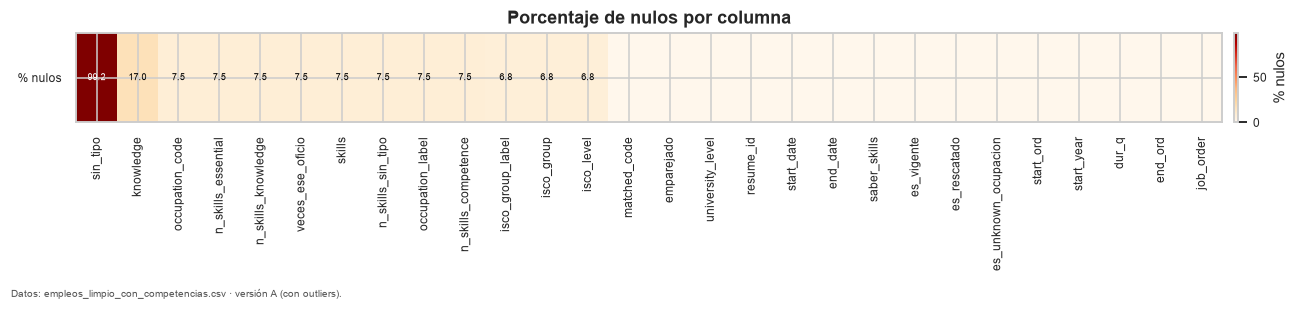

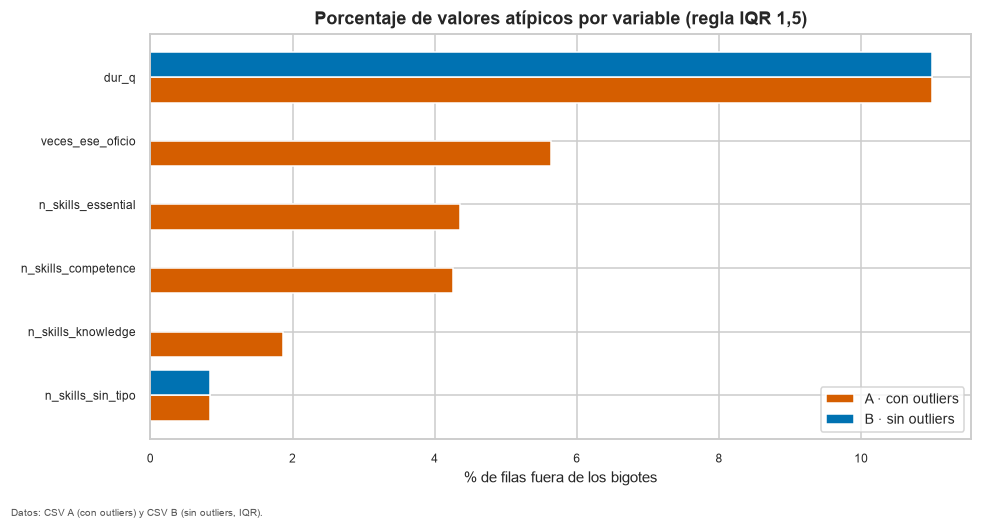

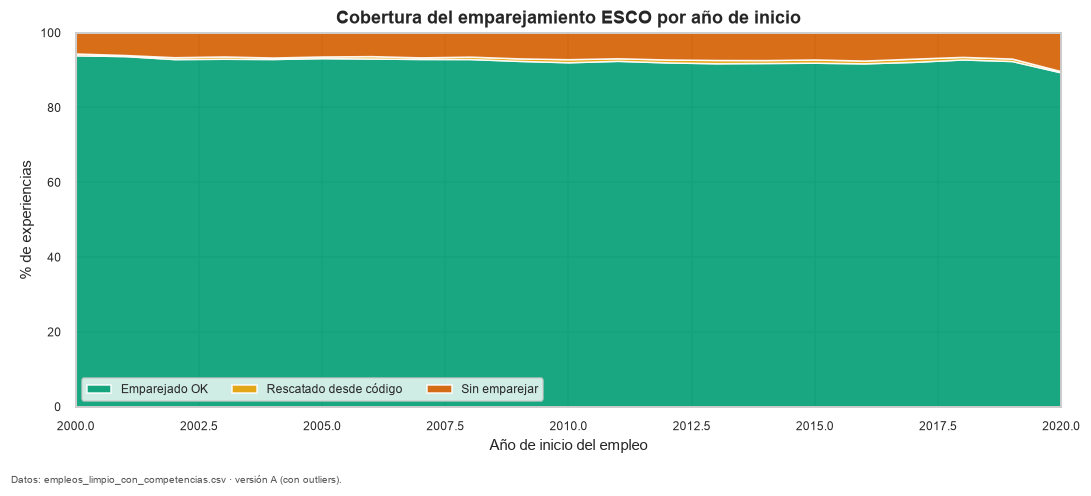

In [4]:
figures = pipeline.render_quality()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** G08 deja ver que los nulos se concentran en el bloque de oficio y competencias, no en las variables de fecha ni en el identificador. G09 muestra que B reduce los extremos de las cuatro columnas winsorizadas; las demás variables conservan la misma proporción de atípicos, lo que confirma que la winsorización fue selectiva. G10 enseña que la cobertura del emparejamiento es estable en el tiempo: la mayoría de los años mantiene una proporción alta de oficios emparejados y un grupo minoritario sin emparejar. Esa estabilidad refuerza que el nulo de oficio es estructural y no un deterioro reciente de la fuente. Ninguna figura se usa para decidir un nuevo recorte: solo documentan el que ya existe.


## 4. Nivel experiencia: duración, oficio, formación y competencias

**¿Qué hace?** Calcula media, mediana, moda, desviación, cuartiles, IQR, asimetría y curtosis de las variables numéricas de experiencia; cuenta atípicos IQR; identifica los picos de `dur_q`; y compara A con B.

**¿Por qué existe?** La duración es la medida de permanencia del charter, y la concentración en valores redondos es una señal de calidad que puede afectar cualquier conclusión sobre estabilidad. Las competencias y el oficio describen el contenido del empleo.

**¿Qué recibe y qué entrega?** Recibe A y B. Entrega tablas de estadísticos, atípicos, picos y comparación A/B.

**Papel en el proyecto.** Alimenta la descripción del universo y prepara la lectura de G01, G02, G04, G05 y G07.

In [5]:
pipeline.describe()

display(
    pipeline.results.numeric_summary["con_outliers"].rename(
        columns={
            "variable": "variable",
            "n": "n",
            "media": "media",
            "mediana": "mediana",
            "moda": "moda",
            "desv_est": "desv_est",
            "min": "min",
            "q1": "q1",
            "q3": "q3",
            "iqr": "iqr",
            "max": "max",
            "asimetria": "asimetria",
            "curtosis": "curtosis",
        }
    )
)

display(
    pipeline.results.duration_spikes.rename(
        columns={"trimestres": "trimestres", "frecuencia": "experiencias", "pct": "pct"}
    )
)

display(
    pipeline.results.outliers["con_outliers"].rename(
        columns={
            "variable": "variable",
            "limite_inferior": "limite_inferior",
            "limite_superior": "limite_superior",
            "filas_atipicas": "filas_atipicas",
            "pct_atipicas": "pct_atipicas",
            "max_observado": "max_observado",
        }
    )
)

display(
    pipeline.results.ab_comparison.rename(
        columns={
            "variable": "variable",
            "mediana_a": "mediana_a",
            "mediana_b": "mediana_b",
            "media_a": "media_a",
            "media_b": "media_b",
            "max_a": "max_a",
            "max_b": "max_b",
            "desv_a": "desv_a",
            "desv_b": "desv_b",
        }
    )
)

,variable,n,media,mediana,moda,desv_est,min,q1,q3,iqr,max,asimetria,curtosis
0,dur_q,376567,12.486,5.000,2.000,18.475,2.000,2.000,13.000,11.000,213.000,3.292,14.235
1,n_skills_essential,348263,23.260,20.000,20.000,13.324,4.000,15.000,28.000,13.000,99.000,2.251,6.970
2,n_skills_competence,348263,19.244,18.000,20.000,11.179,0.000,12.000,23.000,11.000,69.000,1.925,4.809
3,n_skills_knowledge,348263,4.006,3.000,1.000,4.363,0.000,1.000,6.000,5.000,45.000,3.838,23.685
4,n_skills_sin_tipo,348263,0.010,0.000,0.000,0.106,0.000,0.000,0.000,0.000,2.000,11.686,151.683
5,veces_ese_oficio,348263,1.563,1.000,1.000,1.148,1.000,1.000,2.000,1.000,19.000,3.382,17.692


,trimestres,experiencias,pct
0,2.000,113126,30.040
3,5.000,89577,23.790
7,9.000,34862,9.260
11,13.000,20368,5.410
15,17.000,13327,3.540
19,21.000,9524,2.530
1,3.000,9474,2.520
2,4.000,7136,1.900
23,25.000,6415,1.700
27,29.000,5071,1.350


,variable,limite_inferior,limite_superior,filas_atipicas,pct_atipicas,max_observado
0,dur_q,-14.500,29.500,41410,11.000,213.000
1,n_skills_essential,-4.500,47.500,16394,4.350,99.000
2,n_skills_competence,-4.500,39.500,16054,4.260,69.000
3,n_skills_knowledge,-6.500,13.500,7004,1.860,45.000
4,n_skills_sin_tipo,0.000,0.000,3180,0.840,2.000
5,veces_ese_oficio,-0.500,3.500,21244,5.640,19.000


,variable,mediana_a,mediana_b,media_a,media_b,max_a,max_b,desv_a,desv_b
0,dur_q,5.000,5.000,12.486,12.486,213.000,213.000,18.475,18.475
1,n_skills_essential,20.000,20.000,23.260,22.233,99.000,47.500,13.324,9.910
2,n_skills_competence,18.000,18.000,19.244,18.434,69.000,39.500,11.179,8.653
3,n_skills_knowledge,3.000,3.000,4.006,3.772,45.000,13.500,4.363,3.166
4,n_skills_sin_tipo,0.000,0.000,0.010,0.010,2.000,2.000,0.106,0.106
5,veces_ese_oficio,1.000,1.000,1.563,1.465,19.000,3.500,1.148,0.784


**Lectura.** La duración tiene una cola larga y picos en valores redondos: la fuente registra duraciones "a ojo" en algunos tramos. Eso no invalida `dur_q`, pero obliga a no tratarla como una medida continua perfecta. La asimetría positiva es esperable en trayectorias laborales: muchas experiencias cortas y unas pocas muy largas.

La comparación A/B confirma que la winsorización cambia los máximos y la dispersión de las cuatro columnas tratadas, pero no la mediana. Las conclusiones descriptivas sobre el centro de la distribución son, por tanto, robustas a la versión elegida.

**Figuras G01, G02, G03, G04, G05, G06 y G07 · el universo en siete vistas**

**¿Qué hacen?** G01 histograma de duración; G02 top de ocupaciones con bucket "Otras"; G03 caja de duración por grupo ISCO; G04 barras de nivel educativo; G05 histograma de competencias esenciales; G06 perfil medio de competencias por grupo ISCO; G07 experiencias iniciadas por año.

**¿Por qué existen?** Responden las preguntas descriptivas básicas del charter: cuánto dura un empleo, qué oficios concentran la experiencia, si la duración cambia por área, qué formación declara la población, cuántas competencias exige un oficio, cómo se reparte ese perfil por área y qué cobertura temporal tiene la fuente.

**¿Qué reciben y qué entregan?** Reciben el DataFrame A y las tablas de categorías. Entregan siete PNG.

**Fuente de datos.** Las siete figuras usan `empleos_limpio_con_competencias.csv` (A · con outliers).

**Papel en el proyecto.** Son la base de la sección descriptiva del informe y el contexto para interpretar el target.


Figuras generadas: G01, G02, G03, G04, G05, G06, G07


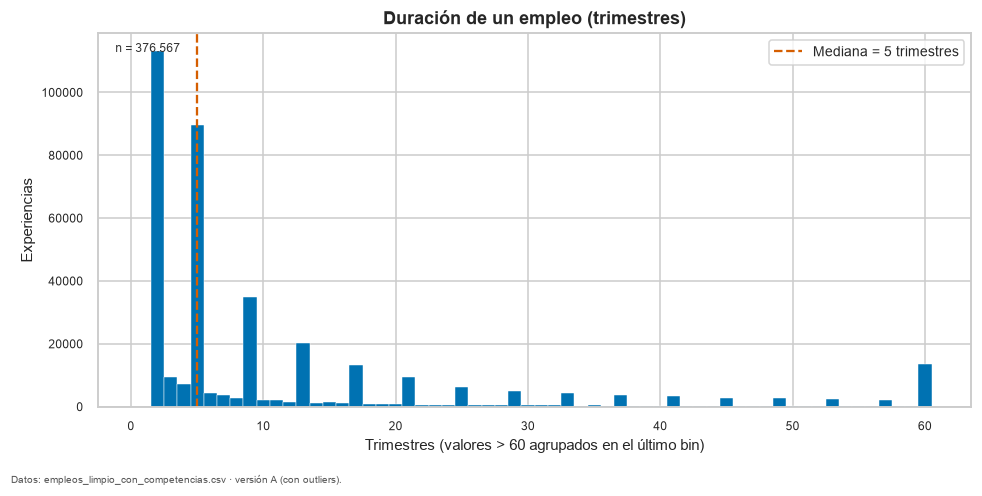

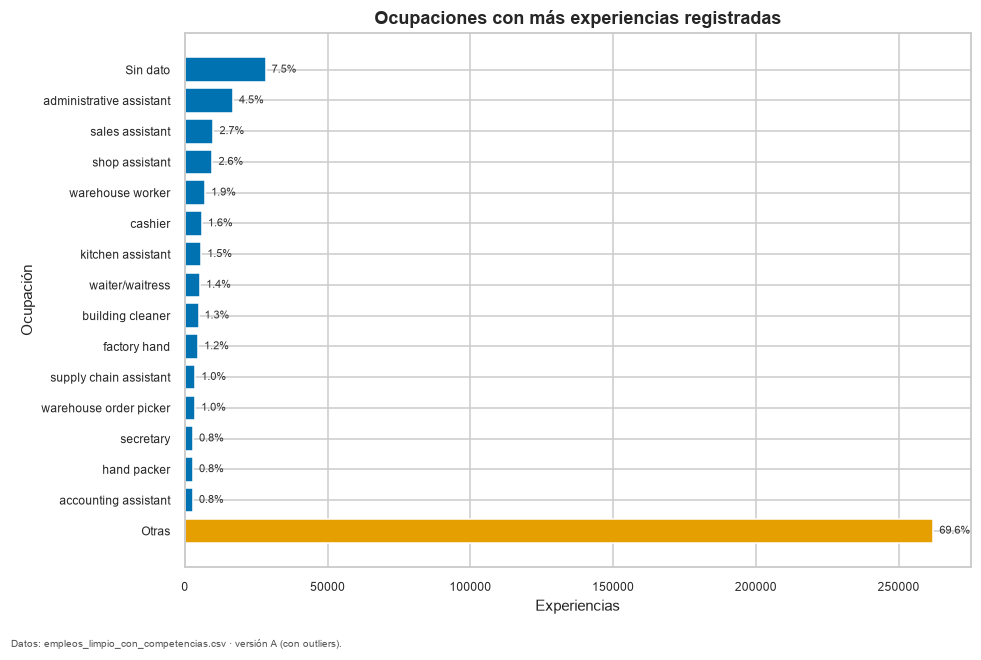

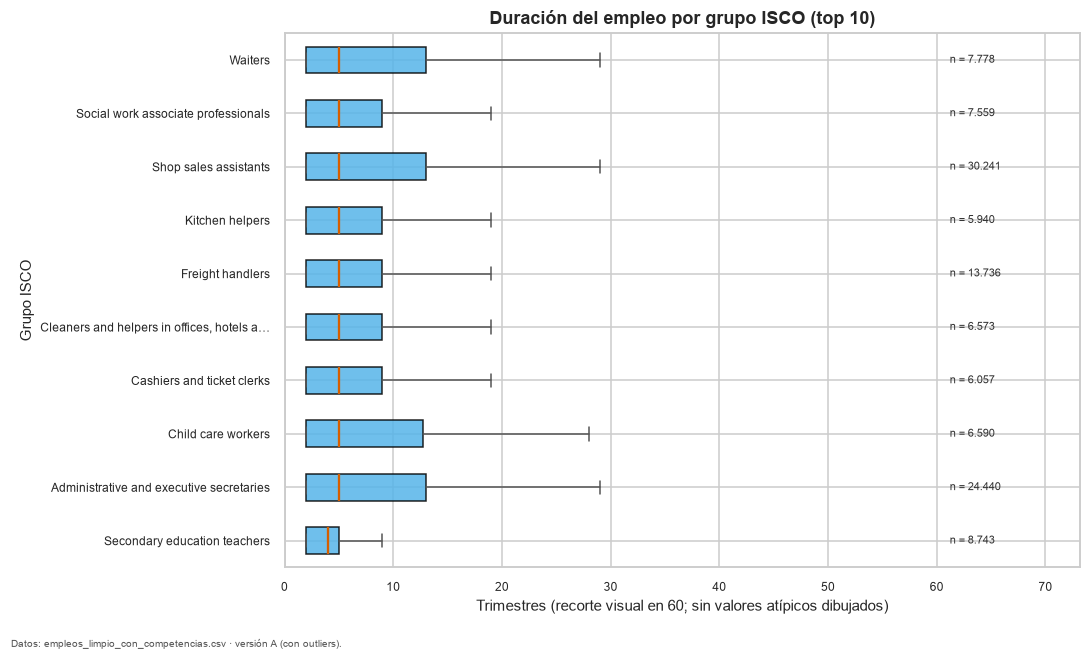

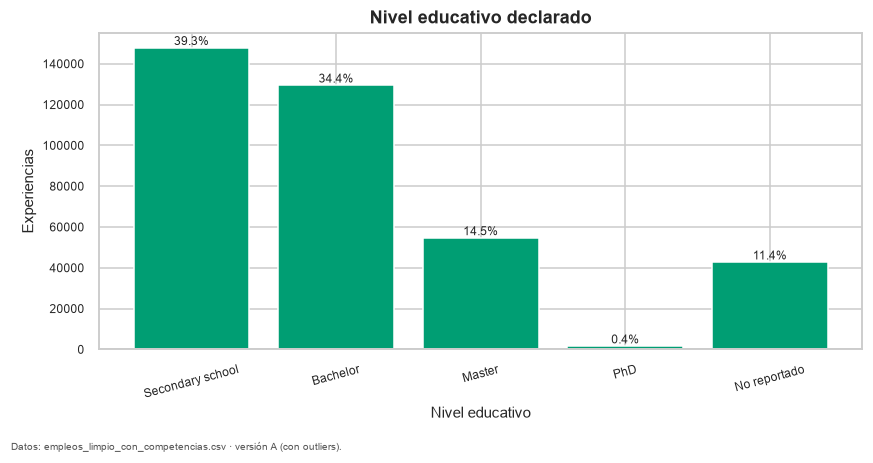

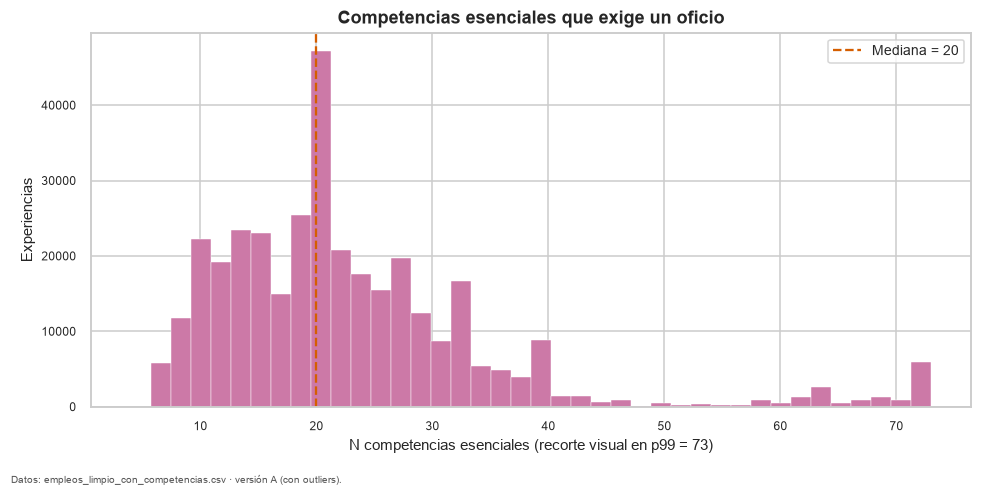

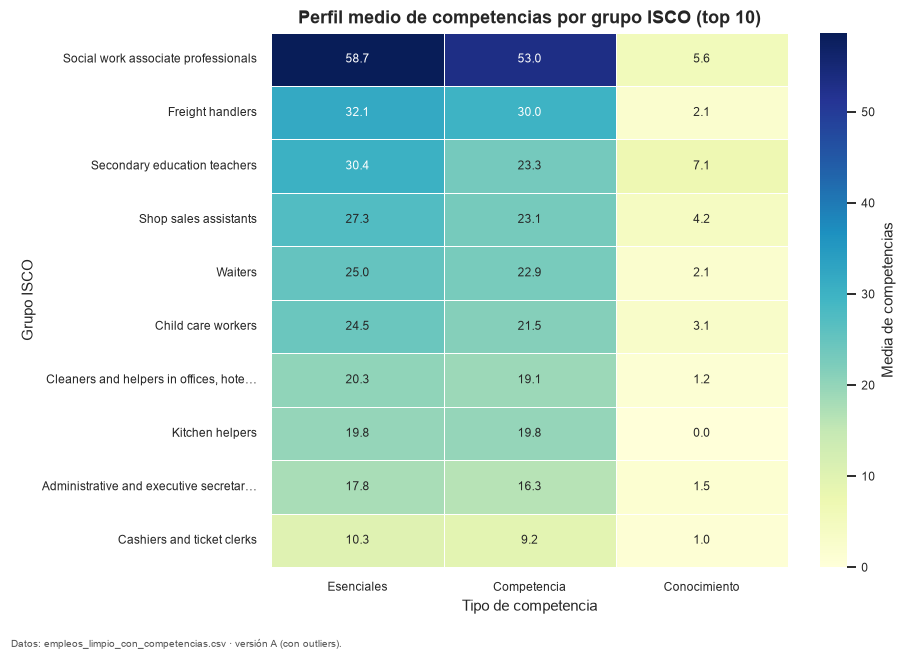

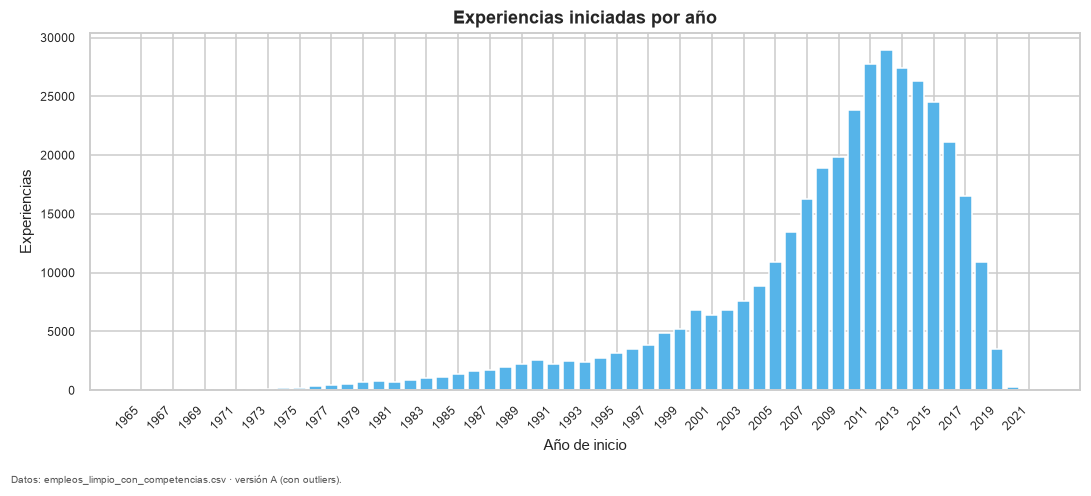

In [6]:
figures = pipeline.render_experience()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** G01 muestra que la duración típica es corta y que la cola larga existe, pero está muy concentrada. G02 confirma que el universo está dominado por un puñado de oficios de ventas, administración y atención al cliente; el bucket "Otras" evita que la cola de etiquetas raras distorsione la lectura. G03 ordena los grupos ISCO por mediana de duración: las diferencias existen, pero el orden de magnitud se mantiene corto en casi todas las áreas. G04 enseña una población con formación mayoritariamente secundaria y de grado, con un grupo importante que no reporta nivel. G05 indica que la mayoría de los oficios exige un número moderado de competencias esenciales, con una cola de oficios muy especializados. G06 muestra que el perfil de competencias cambia por área: unas pesan más en competencias esenciales y otras en conocimiento, lo que anticipa que el área ocupacional aporta señal descriptiva. G07 muestra que la cobertura temporal no es uniforme: hay años con mucha más actividad registrada, lo que puede reflejar tanto el mercado como la forma de captura.

Ninguna de estas figuras se cruza con el target: son descriptivas y sirven para saber qué hay antes de preguntar por la reincidencia.


## 5. Nivel persona: volumen, retornos y movilidad

**¿Qué hace?** Agrega la tabla de experiencias por `resume_id` y calcula número de empleos, oficios distintos, duración total, lapso de la trayectoria, ratio de solapamiento, retornos, autolazos y ratio de exploración.

**¿Por qué existe?** El charter habla de trayectorias, no solo de empleos. La persona es la unidad correcta para medir permanencia y retorno. `resume_id` se usa solo como clave de agrupación.

**¿Qué recibe y qué entrega?** Recibe el DataFrame A. Entrega una tabla con una fila por persona y tres tablas de resumen: distribución de empleos, distribución de retornos y estadísticos de las medidas de trayectoria.

**Papel en el proyecto.** Alimenta G11, G13 y G15, y es la base del segmento derivado de la sección 11.

In [7]:
pipeline.person_level()

display(
    pipeline.results.person_summary.rename(
        columns={
            "variable": "variable",
            "media": "media",
            "mediana": "mediana",
            "q1": "q1",
            "q3": "q3",
            "max": "max",
        }
    )
)

display(
    pipeline.results.job_distribution.rename(
        columns={
            "n_jobs": "empleos",
            "personas": "personas",
            "pct": "pct",
            "pct_acumulado": "pct_acumulado",
        }
    )
)

display(
    pipeline.results.returns_distribution.rename(
        columns={"retornos": "retornos", "personas": "personas", "pct": "pct"}
    )
)

,variable,media,mediana,q1,q3,max
0,n_jobs,5.299,5.000,3.000,7.000,20.000
1,n_occ,4.011,4.000,2.000,5.000,18.000
2,span_q,55.412,44.000,24.000,79.000,233.000
3,dur_total,66.166,47.000,23.000,89.000,"1,677.000"
4,dur_mean,14.343,9.000,5.000,17.333,195.000
5,n_returns,0.890,0.000,0.000,1.000,18.000
6,overlap_ratio,1.181,1.019,0.901,1.241,13.345
7,self_loop_share,0.115,0.000,0.000,0.167,1.000
8,exploration_ratio,0.794,0.833,0.667,1.000,1.000


,empleos,personas,pct,pct_acumulado
0,1,4369,6.150,6.150
1,2,7686,10.820,16.970
2,3,10148,14.280,31.250
3,4,10613,14.940,46.190
4,5,9594,13.500,59.690
5,6,7957,11.200,70.890
6,7,6281,8.840,79.730
7,8,4448,6.260,85.990
8,9,3282,4.620,90.610
9,10,2319,3.260,93.870


,retornos,personas,pct
0,0 retornos,38661,54.410
1,1 retorno,16941,23.840
2,2 o más retornos,15459,21.750


**Lectura.** La mayoría de las personas tiene entre tres y siete empleos registrados; hay una minoría con trayectorias muy largas. El número de oficios distintos es menor que el número de empleos, lo que ya insinúa autolazos o retornos. La distribución de retornos separa a quienes nunca vuelven a un oficio previo de quienes vuelven una o más veces; ese grupo es el que el target etiqueta a nivel experiencia.

El ratio de solapamiento medio es cercano a uno, pero su cola muestra personas con empleos simultáneos. Eso importa para las transiciones: un solapamiento puede producir una secuencia que no es un cambio real.

**Figuras G11, G12, G13, G14 y G15 · volumen, trayectoria, retorno y movilidad**

**¿Qué hacen?** G11 histograma de empleos por persona; G12 duración total de la trayectoria; G13 barras de retornos (0, 1, 2+); G14 distribución del autolazo y de la exploración con sus umbrales Q75; G15 hexbin de empleos frente a oficios distintos.

**¿Por qué existen?** G11 responde cuántos empleos tiene una persona; G12, cuánto abarca su trayectoria en el tiempo; G13, cuántas vuelven a un oficio; G14, qué forma tiene la trayectoria y de dónde salen los umbrales del segmento; G15, si la movilidad crece con el volumen o si muchas personas repiten.

**¿Qué reciben y qué entregan?** Reciben la tabla por persona, la tabla del segmento y una muestra determinista para el hexbin. Entregan cinco PNG.

**Fuente de datos.** Las cinco figuras usan la tabla por persona derivada de `empleos_limpio_con_competencias.csv` (A · con outliers).

**Papel en el proyecto.** Sostienen la lectura de trayectoria y preparan el terreno para el segmento.


Figuras generadas: G11, G12, G13, G14, G15


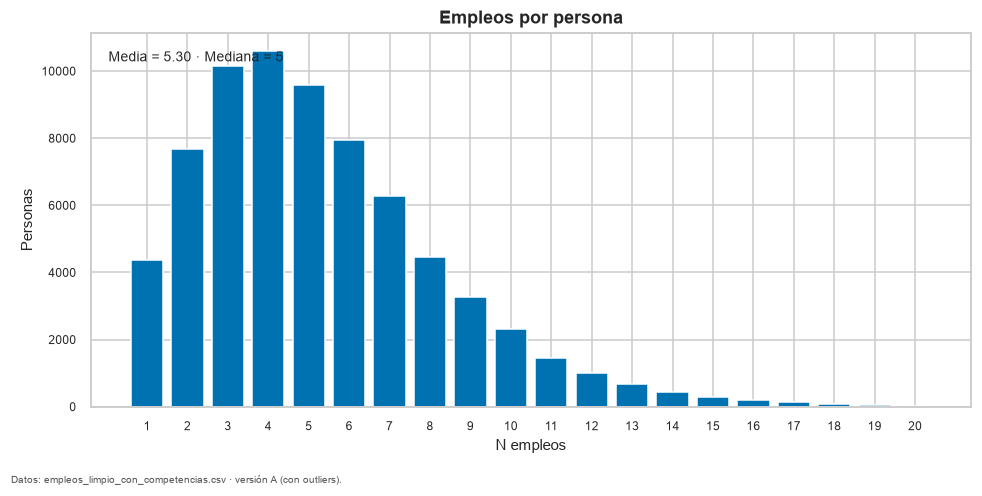

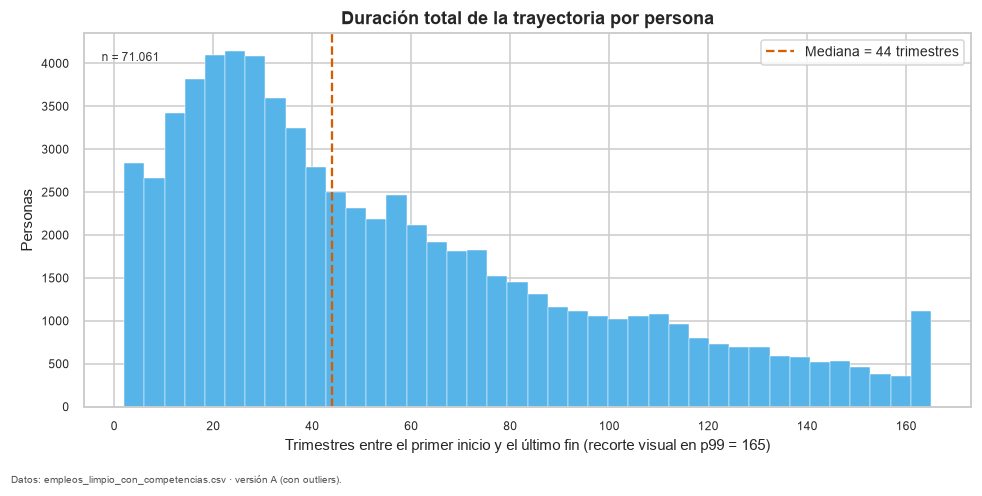

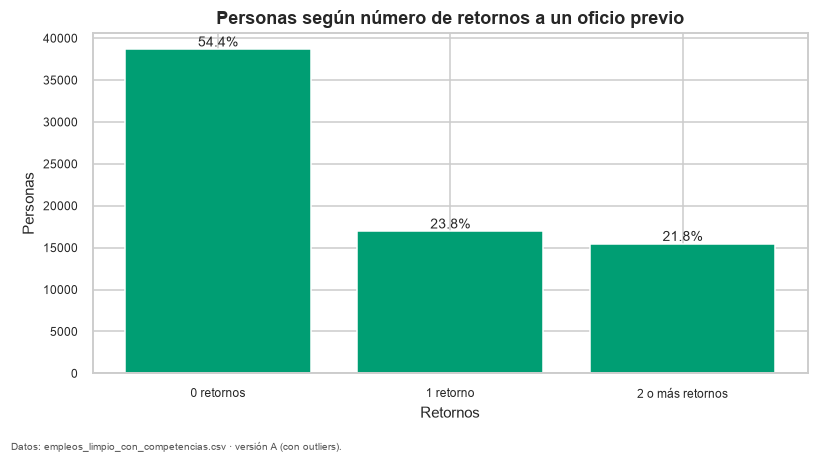

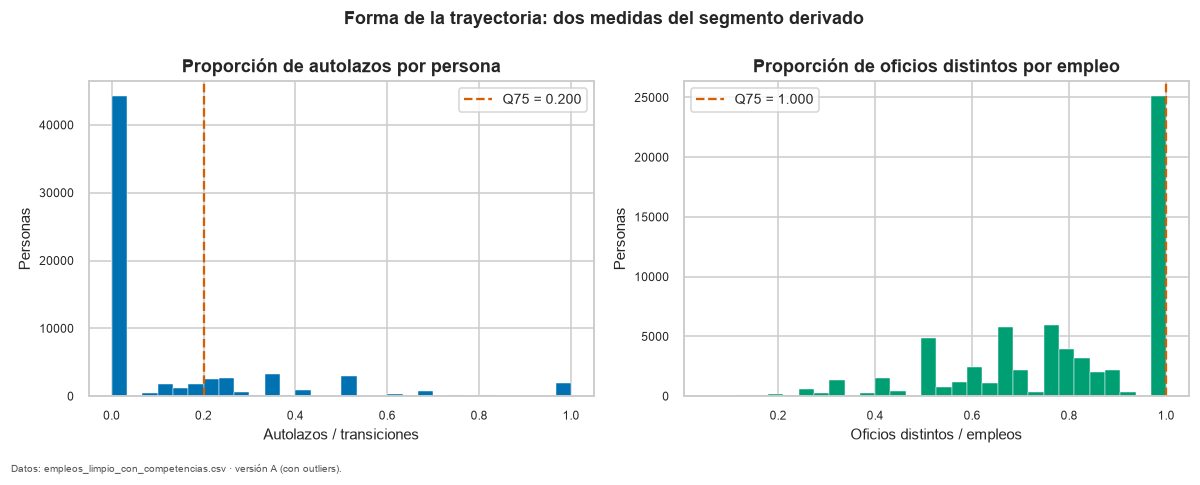

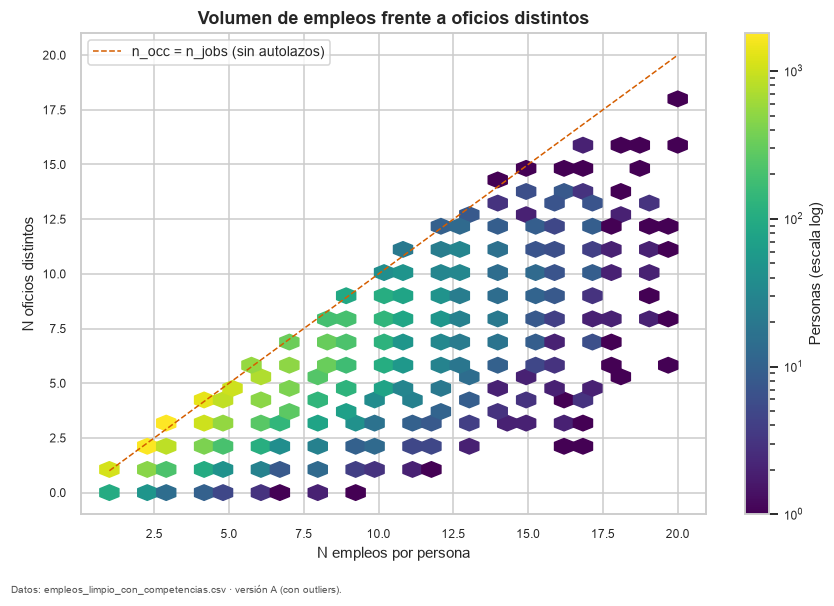

In [8]:
figures = pipeline.render_person()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** G11 muestra una distribución con moda en pocos empleos y una cola hacia trayectorias largas. G12 confirma que la trayectoria típica abarca varios años, con una cola de carreras muy extensas que el recorte visual deja fuera. G13 confirma que una parte relevante de la población vuelve al menos una vez a un oficio previo. G14 es la antesala del segmento: el autolazo se concentra en cero para la mayoría, mientras que la exploración se acumula cerca de uno, y las líneas Q75 marcan exactamente los cortes usados para clasificar. G15 es la lectura clave: si todos los puntos estuvieran sobre la diagonal, cada empleo sería un oficio distinto; la nube por debajo de la diagonal indica autolazos y repetición. La densidad se concentra en el rango bajo de empleos, así que las trayectorias extremas son pocas pero muy visibles.


## 6. Transiciones: autolazos, cambios de área y retornos

**¿Qué hace?** Construye una fila por par consecutivo de empleos clasificados, marca autolazos (mismo oficio), cambios dentro del mismo ISCO y retornos no adyacentes; resume las transiciones más frecuentes y prepara las matrices oficio→oficio e ISCO→ISCO.

**¿Por qué existe?** Es el corazón descriptivo del charter: qué movimientos se repiten. La matriz fina captura cambios entre oficios parecidos que el ISCO agregado esconde; la matriz ISCO muestra los cambios de área.

**¿Qué recibe y qué entrega?** Recibe el DataFrame A. Entrega la tabla de transiciones, un resumen, el top de movimientos, tasas por oficio de origen y las dos matrices.

**Papel en el proyecto.** Alimenta G20 y G21 y la sección de patrones de transición del informe.

In [9]:
pipeline.transition_analysis()

display(pd.DataFrame([pipeline.results.transition_summary]).T.rename(columns={0: "valor"}))
display(pipeline.results.top_moves.head(20))
display(pipeline.results.transition_rates)
display(pipeline.results.return_stats)

print(
    "Matriz oficio→oficio:",
    pipeline.results.occupation_matrix.shape,
    "· Matriz ISCO→ISCO:",
    pipeline.results.isco_matrix.shape,
)

,valor
n_transitions,"277,866.000"
n_persons,"65,076.000"
self_loop_pct,12.570
same_isco_pct,17.430
median_gap_q,0.000
overlap_pct,59.730


,source_label,dest_label,transiciones,pct_del_total
0,sales assistant,administrative assistant,500,0.180
1,administrative assistant,sales assistant,457,0.160
2,shop assistant,administrative assistant,416,0.150
3,administrative assistant,shop assistant,369,0.130
4,sales assistant,shop assistant,348,0.130
5,shop assistant,sales assistant,323,0.120
6,administrative assistant,secretary,322,0.120
7,secretary,administrative assistant,318,0.110
8,cashier,shop assistant,302,0.110
9,administrative assistant,accounting assistant,296,0.110


,source_label,transiciones,autolazo_pct,mismo_isco_pct
1,administrative assistant,13512,24.880,28.370
9,sales assistant,8430,20.510,29.470
4,shop assistant,7767,16.480,25.560
6,warehouse worker,5635,17.070,23.000
7,cashier,4955,13.300,13.340
0,waiter/waitress,4567,12.310,14.520
5,kitchen assistant,4538,17.890,18.140
8,factory hand,3852,14.070,14.070
3,building cleaner,3665,18.470,20.790
14,supply chain assistant,2817,12.740,21.300


,tipo,transiciones,pct
0,Autolazo (mismo oficio consecutivo),34938,12.570
1,Retorno no adyacente,28312,10.190
2,Cambio a otro oficio (sin retorno),214616,77.240


Matriz oficio→oficio: (20, 20) · Matriz ISCO→ISCO: (15, 15)


**Lectura.** El autolazo es una parte no trivial de las transiciones: la persona cambia de empleo pero no de oficio. El cambio dentro del mismo ISCO también es frecuente, lo que sugiere movimientos laterales entre ocupaciones parecidas. El top de movimientos está dominado por idas y vueltas entre ventas, administración y atención al cliente; son los mismos nodos que concentraban la experiencia en G02.

Los retornos no adyacentes son menos frecuentes que los autolazos, pero existen: la persona deja un oficio, prueba otro y vuelve. Esa es exactamente la evidencia descriptiva que el charter pide, y es la razón por la que el target binario se queda corto: etiqueta la repetición, no la forma del movimiento.

**Figuras G16, G20, G21 y G22 · transiciones finas, agregadas y tasas por origen**

**¿Qué hacen?** G16 barras de los 20 pares origen→destino más frecuentes sin autolazos; G20 heatmap de las 20 ocupaciones más activas; G21 heatmap de los grupos ISCO más activos; G22 tasas de autolazo y de permanencia en el mismo ISCO por ocupación de origen.

**¿Por qué existen?** G16 responde qué movimientos concretos se repiten; G20 y G21, qué estructura tienen esos movimientos en lo fino y en lo agregado; G22, qué ocupaciones concentran la repetición y si el área ISCO esconde movimientos laterales.

**¿Qué reciben y qué entregan?** Reciben la tabla de movimientos, las matrices de conteo y la tabla de tasas por origen. Entregan cuatro PNG.

**Fuente de datos.** Las cuatro figuras usan las transiciones derivadas de `empleos_limpio_con_competencias.csv` (A · con outliers).

**Papel en el proyecto.** Son la evidencia visual principal de la sección de transiciones.


Figuras generadas: G16, G20, G21, G22


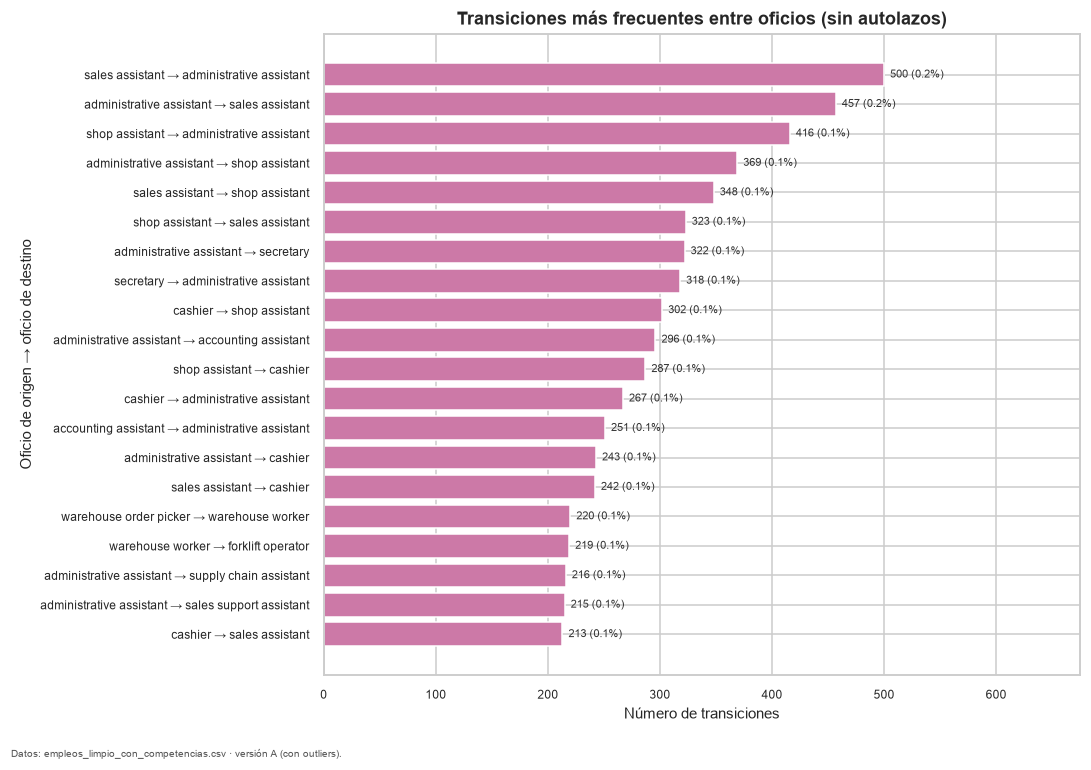

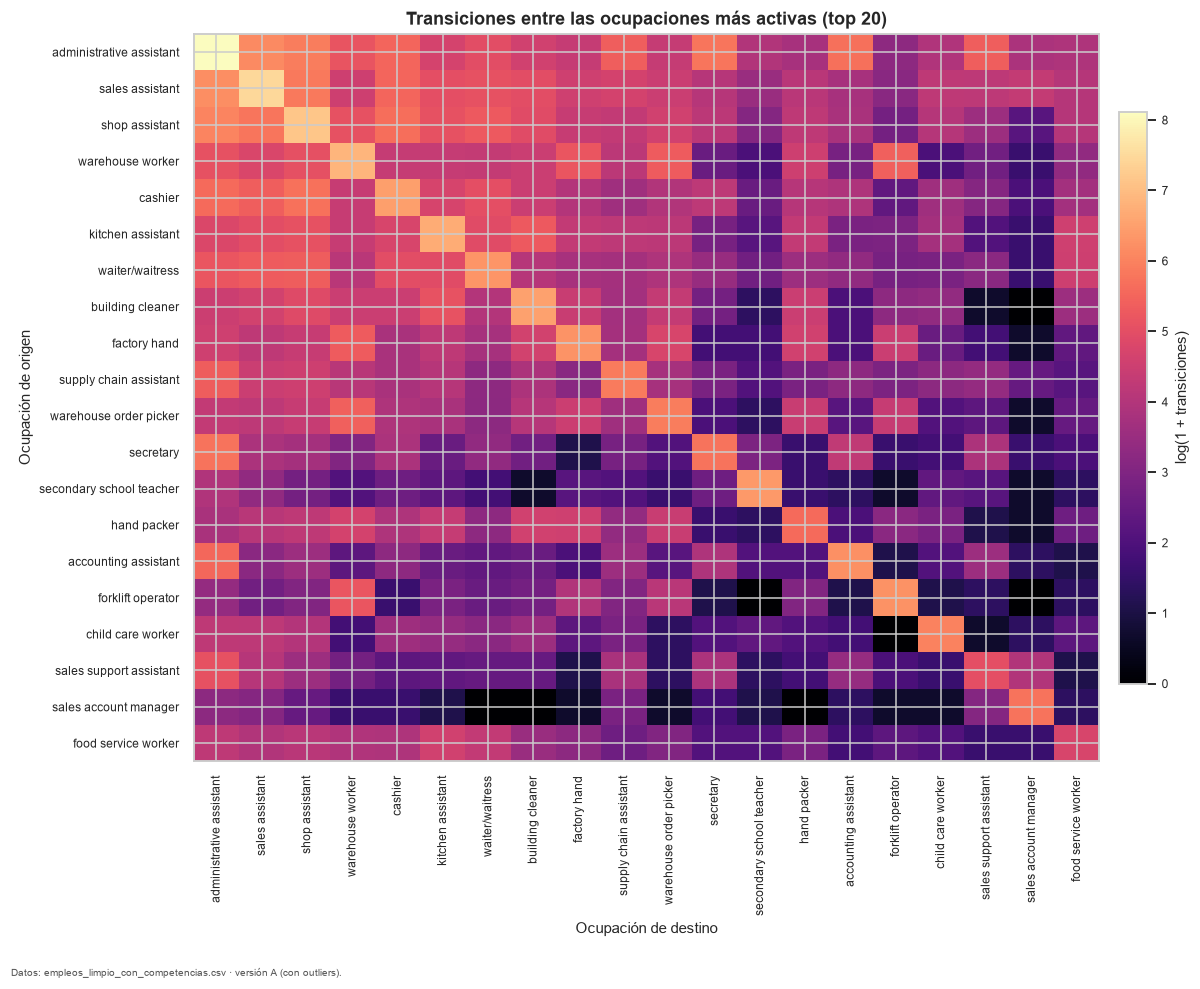

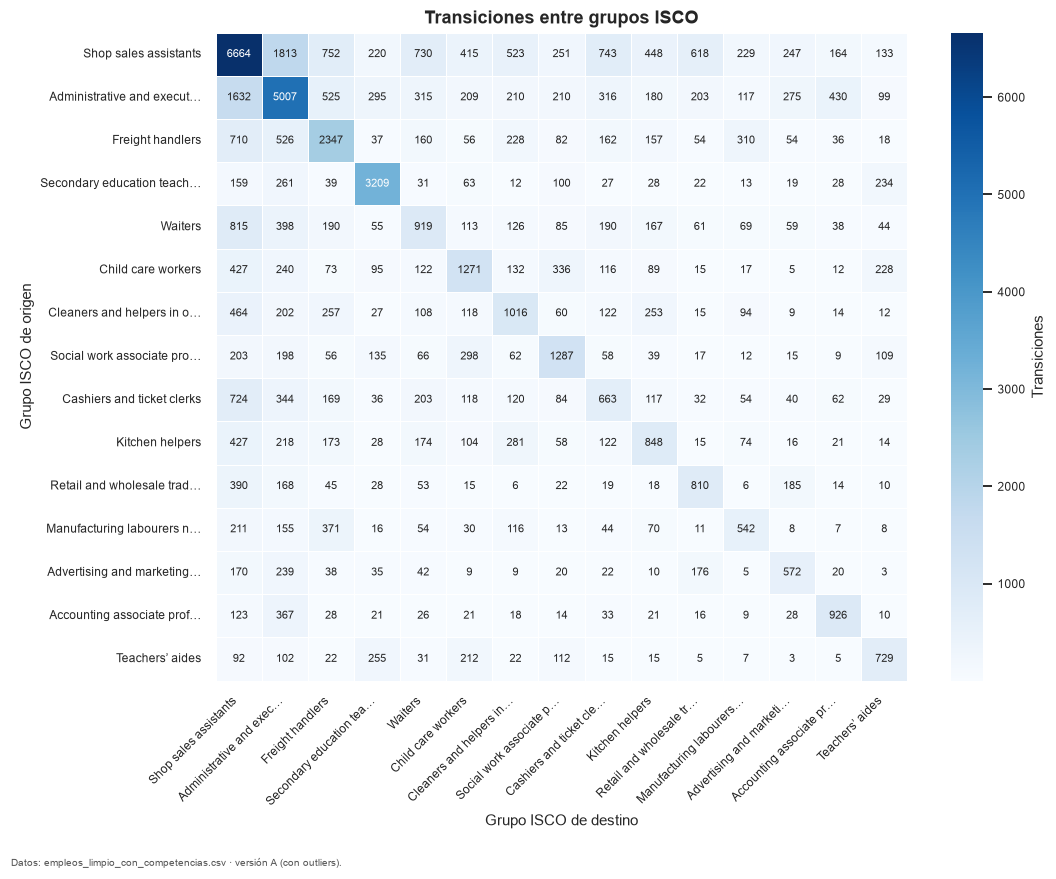

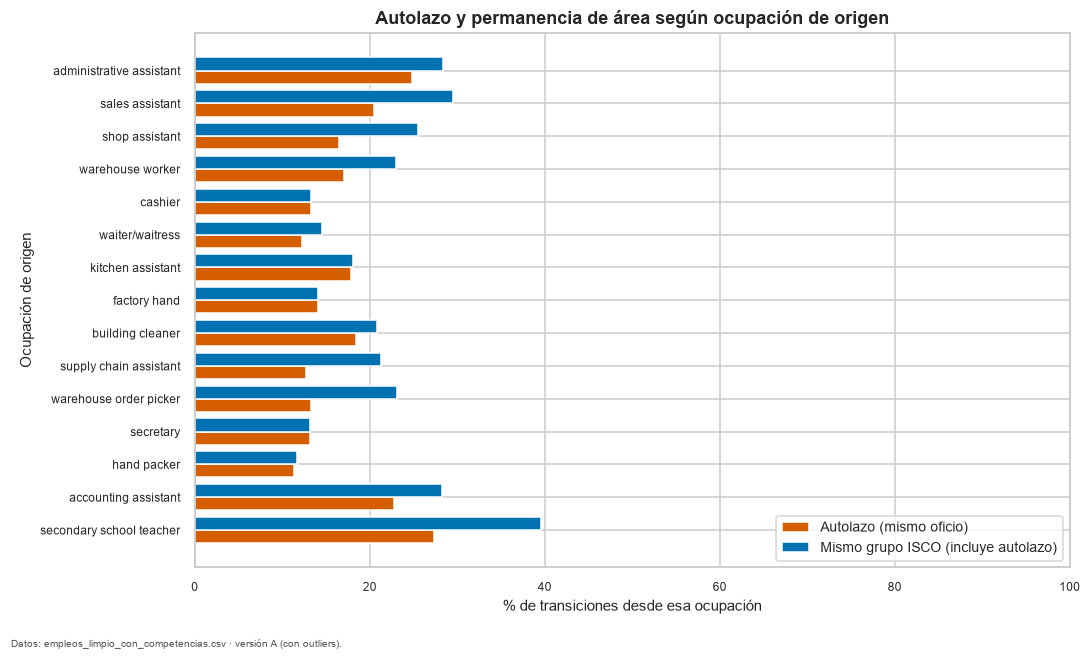

In [10]:
figures = pipeline.render_transitions()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** G16 pone nombre y número a los movimientos más frecuentes: idas y vueltas entre ventas, administración y atención al cliente. G20 confirma que esos pares forman bloques intensos en la diagonal y en un triángulo reducido de ocupaciones parecidas; G21 muestra que, al agregar por ISCO, la diagonal sigue pesando pero aparecen flujos entre áreas de servicio, educación y administración. G22 añade el matiz importante: hay ocupaciones donde el autolazo es alto y otras donde lo que domina es el cambio dentro del mismo ISCO, es decir, movimiento lateral sin salir del área. La lectura de negocio es que la trayectoria típica no es una escalera vertical: es una rotación dentro de un mismo espacio de tareas, con algunos puentes entre áreas.


## 7. Bivariado y colinealidad

**¿Qué hace?** Calcula las matrices de Pearson y Spearman, lista los pares con correlación absoluta alta y declara las familias redundantes por construcción.

**¿Por qué existe?** El encargo exige no usar variables muy correlacionadas como si fueran evidencia independiente. Este bloque es la guarda que impide leer `dur_q`, `dur_total` y `span_q` como tres hallazgos distintos, o `n_skills_essential` y `n_skills_competence` como dos señales separadas.

**¿Qué recibe y qué entrega?** Recibe el DataFrame A y la lista de variables numéricas. Entrega las dos matrices, la tabla de pares altos y las familias declaradas.

**Papel en el proyecto.** Alimenta G17 y la advertencia metodológica de la fase 4.

In [11]:
pipeline.bivariate()

display(pipeline.results.pearson.round(3))
display(
    pipeline.results.high_pairs.rename(
        columns={
            "variable_a": "variable_a",
            "variable_b": "variable_b",
            "pearson": "pearson",
            "spearman": "spearman",
            "strength": "intensidad",
        }
    )
)
display(
    pipeline.describer.collinearity_families().rename(
        columns={"familia": "familia", "variables": "variables"}
    )
)

,dur_q,start_ord,end_ord,start_year,job_order,n_skills_essential,n_skills_competence,n_skills_knowledge,n_skills_sin_tipo,veces_ese_oficio
dur_q,1.000,-0.369,0.212,-0.367,-0.130,-0.023,-0.030,0.007,-0.007,-0.072
start_ord,-0.369,1.000,0.831,1.000,0.366,0.044,0.054,-0.004,0.017,0.037
end_ord,0.212,0.831,1.000,0.831,0.307,0.032,0.038,-0.000,0.013,-0.005
start_year,-0.367,1.000,0.831,1.000,0.366,0.044,0.054,-0.004,0.017,0.037
job_order,-0.130,0.366,0.307,0.366,1.000,0.053,0.048,0.040,0.002,0.176
n_skills_essential,-0.023,0.044,0.032,0.044,0.053,1.000,0.951,0.616,0.034,0.097
n_skills_competence,-0.030,0.054,0.038,0.054,0.048,0.951,1.000,0.343,-0.016,0.095
n_skills_knowledge,0.007,-0.004,-0.000,-0.004,0.040,0.616,0.343,1.000,0.119,0.054
n_skills_sin_tipo,-0.007,0.017,0.013,0.017,0.002,0.034,-0.016,0.119,1.000,-0.027
veces_ese_oficio,-0.072,0.037,-0.005,0.037,0.176,0.097,0.095,0.054,-0.027,1.000


,variable_a,variable_b,pearson,spearman,intensidad
0,start_ord,start_year,1.000,0.999,muy alta
1,n_skills_essential,n_skills_competence,0.951,0.935,muy alta
2,end_ord,start_year,0.831,0.845,alta
3,start_ord,end_ord,0.831,0.843,alta


,familia,variables
0,duración,"dur_q, dur_total, span_q, start_ord, end_ord"
1,competencias,"n_skills_essential, n_skills_competence, n_skills_knowledge, n_skills_sin_tipo"
2,tamaño de la trayectoria,"n_jobs, n_occ"


**Lectura.** Los pares altos no son sorpresas: `start_ord` y `start_year` son dos codificaciones del mismo tiempo; `n_skills_essential` y `n_skills_competence` comparten la mayor parte de su contenido; `end_ord` y `start_year` se mueven juntos porque ambos describen el calendario. La tabla de familias deja explícito qué variables no deben interpretarse en bloque.

La consecuencia para la fase 4 es doble: no seleccionar features mirando solo la correlación con el target, y no construir un modelo interpretativo con las tres variables de duración a la vez. La correlación se usa aquí para describir redundancia, no para elegir el modelo.

**Figuras G17 y G19 · correlación lineal y de rangos**

**¿Qué hacen?** G17 heatmap de Pearson con anotaciones; G19 dispersión de cada par de variables entre su Pearson y su Spearman.

**¿Por qué existen?** G17 es la vista completa de la redundancia; G19 comprueba si esa redundancia se mantiene cuando se mira el orden de los valores y no solo la relación lineal, algo relevante porque varias variables están muy sesgadas.

**¿Qué reciben y qué entregan?** Reciben las matrices de Pearson y Spearman. Entregan dos PNG.

**Fuente de datos.** Ambas figuras usan las variables numéricas de `empleos_limpio_con_competencias.csv` (A · con outliers).

**Papel en el proyecto.** Cierra la sección de colinealidad y queda como referencia para la selección de features.


Figuras generadas: G17, G19


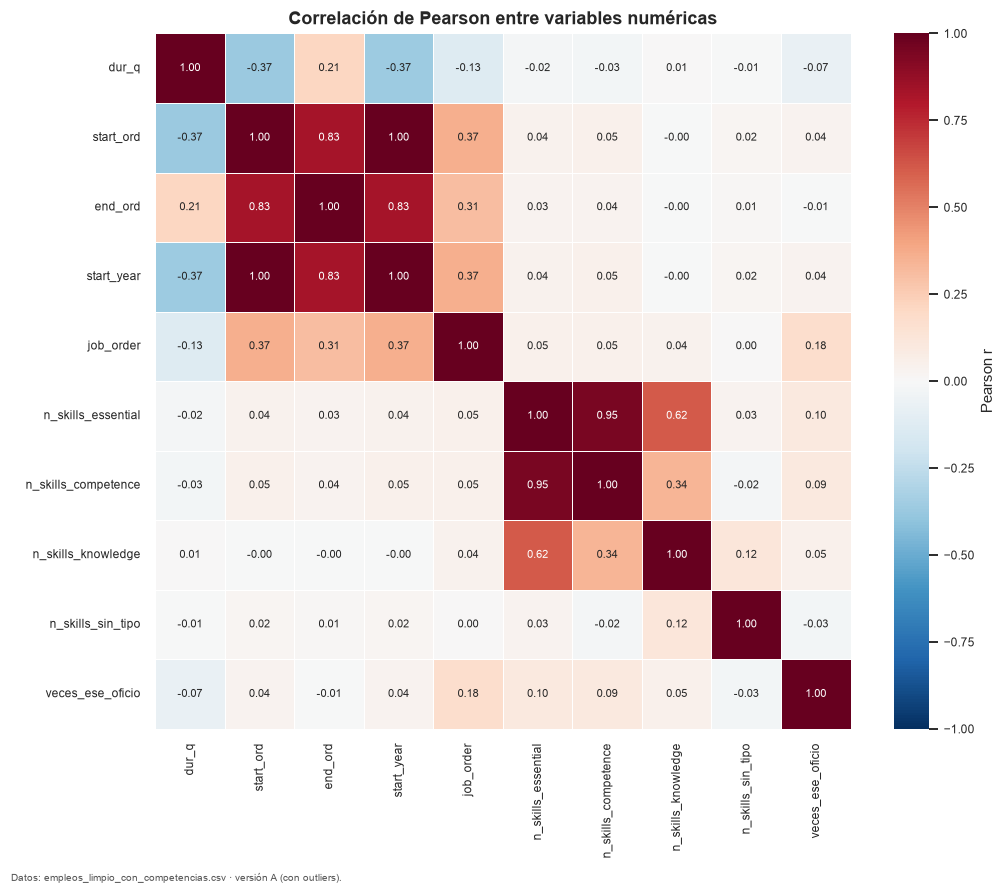

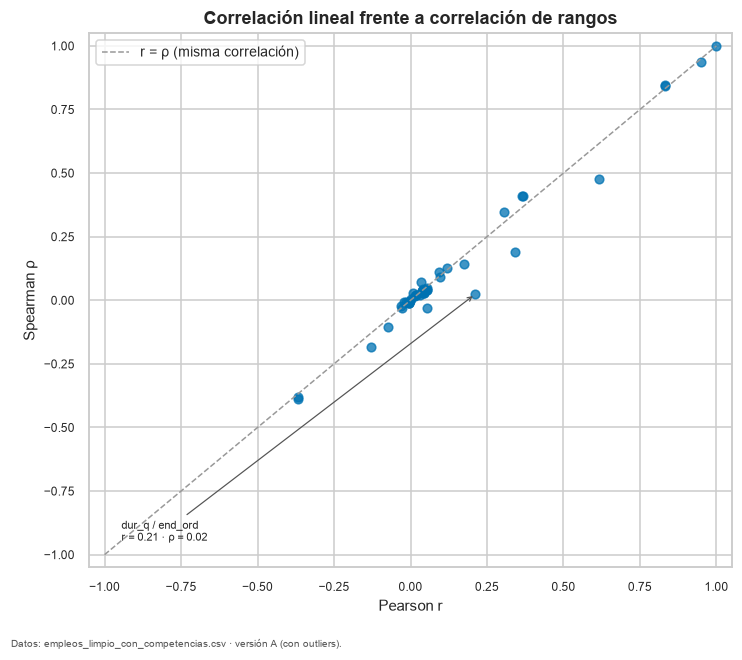

In [12]:
figures = pipeline.render_bivariate()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** El bloque superior izquierdo concentra las correlaciones temporales; el bloque de competencias aparece como una franja muy intensa; las variables de repetición se separan del resto. G19 muestra que la mayoría de los pares se mantiene cerca de la diagonal, así que la redundancia no es un artefacto de la escala; los pares que más se separan son los que combinan variables sesgadas, y por eso se reportan con ambas medidas. La figura no prueba causalidad: solo ordena la redundancia. Cualquier lectura que sume dos variables de la misma familia estará contando dos veces el mismo fenómeno.


## 8. Evidencia PCA reutilizada

**¿Qué hace?** Lee las salidas guardadas de `4.0_PCA.ipynb` y `4.1_PCA_completo.ipynb`, extrae la varianza explicada, el número de componentes para 80 % y 90 %, y los loadings principales; compara las dos muestras.

**¿Por qué existe?** El EDA no debe rehacer transformaciones. El PCA ya se ajustó en la fase 3 y se guardó en dos tamaños de muestra. Mostrarlos juntos es una prueba de estabilidad, no un nuevo análisis.

**¿Qué recibe y qué entrega?** Recibe los cuadernos guardados. Entrega la tabla de estabilidad, las tablas de varianza y los loadings principales.

**Papel en el proyecto.** Cierra la pregunta de dimensionalidad y deja declarado el límite: el PCA cubre las variables numéricas escaladas, no las 2.839 columnas de `X`.

La tabla **G24** del bloque siguiente no es una figura: es la tabla de cargas principales del PCA, con las variables que más pesan en cada componente. Se muestra como tabla porque su valor está en los nombres y en el signo de las cargas, no en una forma visual.

**Fuente de datos.** G23 y la tabla G24 usan las salidas guardadas de `4.0_PCA.ipynb` (10 k) y `4.1_PCA_completo.ipynb` (50 k); no se reajusta el PCA. Cada salida cubre las versiones con y sin outliers.


In [13]:
pipeline.pca()

display(pipeline.results.pca_stability)
display(
    pipeline.results.pca_components.rename(
        columns={"source": "muestra", "version": "version", "n80": "componentes_80", "n90": "componentes_90"}
    )
)

top_loadings = (
    pipeline.results.pca_loadings.sort_values(
        ["source", "version", "component", "abs_loading"],
        ascending=[True, True, True, False],
    )
    .groupby(["source", "version", "component"], sort=False)
    .head(5)
    .reset_index(drop=True)
)
display(
    top_loadings.rename(
        columns={
            "source": "muestra",
            "version": "version",
            "component": "componente",
            "feature": "variable",
            "abs_loading": "loading_abs",
            "signed_loading": "loading_firmado",
        }
    )
)

,fuente,version,pc1_pct,componentes_80,componentes_90
0,10k,A · con outliers,32.210,4,5
1,50k,A · con outliers,32.430,4,5
2,10k,B · sin outliers,39.090,3,5
3,50k,B · sin outliers,39.460,3,5


,muestra,version,componentes_80,componentes_90
0,10k,con,4,5
1,10k,sin,3,5
2,50k,con,4,5
3,50k,sin,3,5


,muestra,version,componente,variable,loading_abs,loading_firmado
0,10k,con,PC1,dur_q_rob,0.840,0.840
1,10k,con,PC1,start_ord_rob,0.341,-0.341
2,10k,con,PC1,start_year_rob,0.339,-0.339
3,10k,con,PC1,job_order_rob,0.174,-0.174
4,10k,con,PC1,veces_ese_oficio_rob,0.114,-0.114
5,10k,con,PC2,end_ord_rob,0.462,0.462
6,10k,con,PC2,n_skills_essential_rob,0.438,0.438
7,10k,con,PC2,n_skills_competence_rob,0.416,0.416
8,10k,con,PC2,dur_q_rob,0.410,0.410
9,10k,con,PC2,start_year_rob,0.273,0.273


**Lectura.** Las dos muestras coinciden en lo esencial: PC1 explica alrededor de un tercio de la varianza en la versión con outliers y algo más en la versión sin outliers; el número de componentes para 80 % es estable. Los loadings de PC1 están dominados por la duración y el tiempo, lo que confirma que el primer eje es un eje de permanencia/calendario, no un eje de contenido del oficio.

El límite queda claro: este PCA no justifica reducir las 2.839 columnas de `X`. Un PCA sobre dummies mezclaría escalas y categorías sin una interpretación limpia. La fase 4 debe decidir la dimensionalidad con criterios supervisados, no con este diagnóstico.

**Figura G23 · estabilidad del PCA**

**¿Qué hace?** Superpone la varianza acumulada de las muestras de 10 k y 50 k, con y sin outliers, y marca el 80 %.

**¿Por qué existe?** Una sola muestra podría ser un artefacto; dos muestras que coinciden son evidencia de estabilidad.

**¿Qué recibe y qué entrega?** Recibe las tablas de varianza y componentes. Entrega un PNG.

**Papel en el proyecto.** Documenta que el diagnóstico de la fase 3 es robusto y que no hace falta repetirlo.

**Fuente de datos.** Salidas guardadas de `4.0_PCA.ipynb` y `4.1_PCA_completo.ipynb` (versiones con y sin outliers).


Figuras generadas: G23


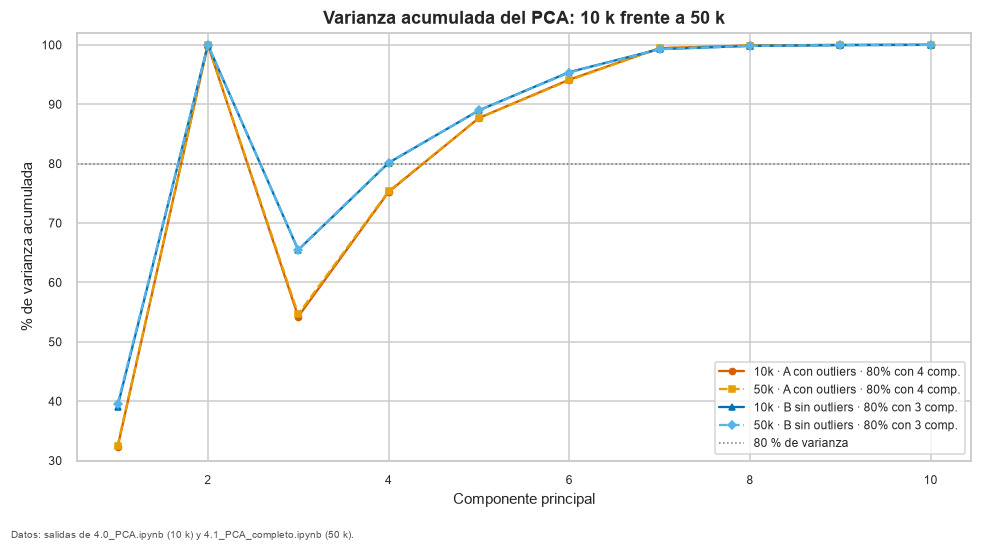

In [14]:
figures = pipeline.render_pca()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** Las curvas de 10 k y 50 k se solapan casi por completo. La versión sin outliers necesita menos componentes porque el recorte reduce la influencia de la cola. La línea del 80 % cruza en el mismo tramo en ambas muestras. Esa coincidencia es la prueba de estabilidad que se buscaba; no se interpreta como una recomendación de número de componentes para el modelo supervisado.

## 9. Comparación A/B y diagnóstico hipotético de `dur_q`

**¿Qué hace?** Compara los estadísticos de A y B y calcula qué pasaría si se winsorizara `dur_q` con los límites IQR: límites, filas recortadas, mediana, media y máximo antes y después.

**¿Por qué existe?** La versión B no winsoriza la duración. Antes de decidir si hay que volver al 2.0, conviene saber cuánto cambiaría y si el cambio afectaría las conclusiones. El diagnóstico es gratis: se hace en RAM y no escribe ningún archivo.

**¿Qué recibe y qué entrega?** Recibe A y B. Entrega la tabla comparativa y una tabla de una fila con el escenario hipotético.

**Papel en el proyecto.** Es la evidencia para la decisión de la iteración: mantener `dur_q` como está o proponer un cambio en la fase 2.

In [15]:
display(
    pipeline.results.ab_comparison.rename(
        columns={
            "variable": "variable",
            "mediana_a": "mediana_a",
            "mediana_b": "mediana_b",
            "media_a": "media_a",
            "media_b": "media_b",
            "max_a": "max_a",
            "max_b": "max_b",
            "desv_a": "desv_a",
            "desv_b": "desv_b",
        }
    )
)

whatif = pd.DataFrame([pipeline.results.whatif]).rename(
    columns={
        "column": "variable",
        "lower": "limite_inferior",
        "upper": "limite_superior",
        "rows_clipped": "filas_recortadas",
        "pct_clipped": "pct_recortado",
        "median_before": "mediana_antes",
        "median_after": "mediana_despues",
        "mean_before": "media_antes",
        "mean_after": "media_despues",
        "max_before": "max_antes",
        "max_after": "max_despues",
    }
)
display(whatif)

,variable,mediana_a,mediana_b,media_a,media_b,max_a,max_b,desv_a,desv_b
0,dur_q,5.000,5.000,12.486,12.486,213.000,213.000,18.475,18.475
1,n_skills_essential,20.000,20.000,23.260,22.233,99.000,47.500,13.324,9.910
2,n_skills_competence,18.000,18.000,19.244,18.434,69.000,39.500,11.179,8.653
3,n_skills_knowledge,3.000,3.000,4.006,3.772,45.000,13.500,4.363,3.166
4,n_skills_sin_tipo,0.000,0.000,0.010,0.010,2.000,2.000,0.106,0.106
5,veces_ese_oficio,1.000,1.000,1.563,1.465,19.000,3.500,1.148,0.784


,variable,limite_inferior,limite_superior,filas_recortadas,pct_recortado,mediana_antes,mediana_despues,media_antes,media_despues,max_antes,max_despues
0,dur_q,-14.500,29.500,41410,11.000,5.000,5.000,12.486,9.535,213.000,29.500


**Lectura.** La winsorización de B cambia los máximos y la dispersión de las cuatro columnas tratadas, pero no las medianas. En el escenario hipotético, recortar `dur_q` por IQR afectaría a una parte apreciable de las filas y reduciría mucho el máximo y la media, aunque la mediana quedaría igual. Eso significa que la cola larga son carreras reales, no ruido de captura: recortarla cambiaría la forma de la distribución, no el centro.

La recomendación es **no** winsorizar `dur_q` en esta iteración. Si se decidiera hacerlo, habría que volver al 2.0, documentar el cambio y re-ejecutar 3.0; no se hace aquí.

**Figura G25 · comparación A/B y what-if de duración**

**¿Qué hace?** Panel izquierdo: dumbbell de medianas A vs B. Panel derecho: barras de mediana, media y máximo de `dur_q` antes y después del recorte hipotético, en escala logarítmica.

**¿Por qué existe?** Hace visible que la winsorización selectiva no mueve el centro y que el recorte de duración sería una decisión de fondo.

**¿Qué recibe y qué entrega?** Recibe la tabla comparativa y el escenario hipotético. Entrega un PNG.

**Fuente de datos.** G25 compara `empleos_limpio_con_competencias.csv` (A · con outliers) con `empleos_limpio_con_competencias_sin_outliers.csv` (B · sin outliers, IQR).

**Papel en el proyecto.** Cierra la decisión de la iteración sobre `dur_q`.


Figuras generadas: G25


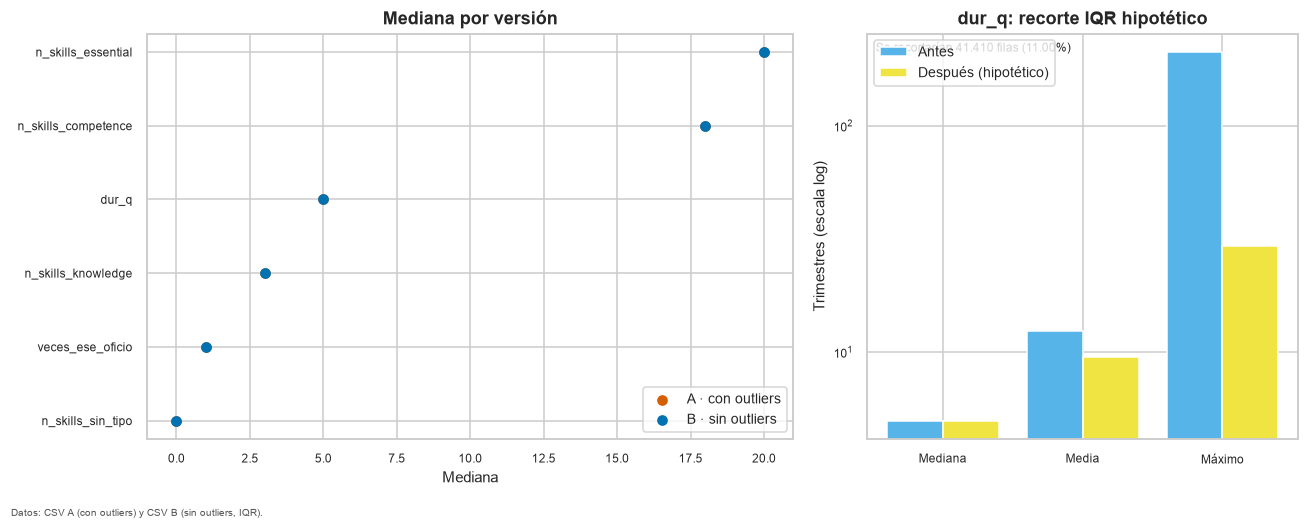

In [16]:
figures = pipeline.render_ab()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** En el panel izquierdo, los puntos de A y B casi se tocan para las variables winsorizadas: el centro no se movió. En el panel derecho, la media y el máximo caen de forma abrupta con el recorte hipotético, mientras la mediana permanece. La figura sostiene la decisión de mantener la versión actual y deja el what-if como evidencia, no como una transformación aplicada.

## 10. Partición por persona y target

**¿Qué hace?** Reconstruye el split por persona con el mismo filtro, el mismo `GroupShuffleSplit` y la misma semilla que usó 3.0; verifica que el target reconstruido coincide fila a fila con `y_train`/`y_test`; y escribe el mapa `resume_id → split` en `reports/eda_jobpath/tables/split_map_resume_id.csv`.

**¿Por qué existe?** El split original no dejó un mapa de personas. Sin ese mapa, cualquier análisis train-only tendría que recalcular la partición y podría desviarse. El mapa hace reproducible la restricción y permite auditar que no hay personas compartidas.

**¿Qué recibe y qué entrega?** Recibe el DataFrame A y los `y` exportados. Entrega el mapa, la verificación y las tablas de train/test con el target adjunto.

**Papel en el proyecto.** Es el puente entre la fase 3 y el análisis supervisado. El mapa es un archivo nuevo, fuera de los insumos, con solo la clave seudónima, el split y el conteo de experiencias.

In [17]:
pipeline.build_split()

verification = pd.DataFrame([pipeline.results.split_verification]).T.rename(columns={0: "valor"})
display(verification)

split_map = pd.read_csv(pipeline.results.split_map_path)
display(split_map.head(10))
display(
    split_map["split"]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="personas")
)
print("Mapa escrito en:", pipeline.results.split_map_path)

train_view = pipeline.train["con_outliers"][
    ["resume_id", "veces_ese_oficio", "reincide", "is_repeated_occupation"]
].head(10)
display(train_view)

,valor
filas_train,"278,987.000"
filas_test,"69,276.000"
personas_train,"56,317.000"
personas_test,"14,080.000"
personas_solapadas,0.000
target_coincide_train_pct,100.000
target_coincide_test_pct,100.000
prevalencia_train_pct,30.520
prevalencia_test_pct,30.460
personas_sin_oficio_clasificado,664.000


,resume_id,split,n_experiences
0,10,train,4
1,100013,train,3
2,100016,train,5
3,100022,train,6
4,10003,test,14
5,100033,train,3
6,100046,train,4
7,100050,train,7
8,100062,train,2
9,100066,train,10


,split,personas
0,train,56317
1,test,14080
2,excluded_no_classified_job,664


Mapa escrito en: C:\Users\User\Documents\JobPath\MineriaProtect\reports\eda_jobpath\tables\split_map_resume_id.csv


,resume_id,veces_ese_oficio,reincide,is_repeated_occupation
0,10,1.000,0,0
1,10,1.000,0,0
2,10,1.000,0,0
3,10,1.000,0,0
4,100013,1.000,0,0
5,100013,1.000,0,0
6,100013,1.000,0,0
7,100016,1.000,0,0
8,100016,1.000,0,0
9,100016,1.000,0,0


**Lectura.** La verificación debe mostrar coincidencia total entre el target reconstruido y el exportado, cero personas compartidas y el mismo tamaño de train/test. El mapa incluye a las personas sin oficio clasificado con la etiqueta `excluded_no_classified_job`: no entran al modelado, pero quedan contadas para que el universo sea auditable.

`is_repeated_occupation` es el nombre recomendado para el target en inglés. Se crea **solo en RAM**, como copia de `reincide`. No se persiste porque eso obligaría a editar `src/transformacion/transformacion.py`, volver a ejecutar 3.0 y actualizar todas las referencias; el procedimiento queda documentado en el cierre del cuaderno.

**¿Qué hace la siguiente caja?** Calcula el balance del target en train y test para A y B, la tasa global con intervalo de Wilson, y las tasas por grupo ISCO, por tramo de duración y por nivel educativo.

**¿Por qué existe?** Es la descripción supervisada mínima antes de modelar: cuánto positivo hay, si el split está balanceado y qué variables se asocian descriptivamente con la etiqueta. Todos los cruces se ejecutan sobre **train**; el test solo se usa para describir el balance, nunca para cruzar features.

**¿Qué recibe y qué entrega?** Recibe las tablas train/test con target. Entrega cuatro tablas de tasas y el registro de usos del guardián.

**Papel en el proyecto.** Alimenta G26, G27, G28 y G29 y las decisiones de métrica de la fase 4.

In [18]:
pipeline.target_analysis()

display(pipeline.results.target_balance)
display(pd.DataFrame([pipeline.results.target_overall]).T.rename(columns={0: "valor"}))
display(pipeline.results.target_by_isco)
display(pipeline.results.target_by_duration)
display(pipeline.results.target_by_education)

,version,split,n,positivos,negativos,tasa_pct
0,A · con outliers,train,278987,85147,193840,30.520
1,A · con outliers,test,69276,21103,48173,30.460
2,B · sin outliers (IQR),train,278987,85147,193840,30.520
3,B · sin outliers (IQR),test,69276,21103,48173,30.460


,valor
n,"278,987.000"
positivos,"85,147.000"
tasa_pct,30.520
ic95_inf_pct,30.350
ic95_sup_pct,30.690


,isco_group_label,n,positivos,tasa_pct,ic95_inf_pct,ic95_sup_pct,grupo_pequeno
0,Shop sales assistants,24238,9099,37.540,36.930,38.150,False
1,Administrative and executive secretaries,19436,9170,47.180,46.480,47.880,False
2,Freight handlers,10927,4112,37.630,36.730,38.540,False
3,Secondary education teachers,7045,4043,57.390,56.230,58.540,False
4,Waiters,6188,1997,32.270,31.120,33.450,False
5,Child care workers,5383,2017,37.470,36.190,38.770,False
6,"Cleaners and helpers in offices, hotels and other establishments",5230,1937,37.040,35.740,38.350,False
7,Social work associate professionals,4953,1636,33.030,31.730,34.350,False
8,Cashiers and ticket clerks,4843,1866,38.530,37.170,39.910,False
9,Kitchen helpers,4734,1871,39.520,38.140,40.920,False


,tramo,n,positivos,tasa_pct,ic95_inf_pct,ic95_sup_pct
0,2–5,160376,54825,34.190,33.950,34.420
1,5–13,53740,14813,27.560,27.190,27.940
2,13–213,64871,15509,23.910,23.580,24.240


,university_level,n,positivos,tasa_pct,ic95_inf_pct,ic95_sup_pct,grupo_pequeno
0,Secondary school,109976,34963,31.790,31.520,32.070,False
1,Bachelor,95363,29660,31.100,30.810,31.400,False
2,Master,40415,10196,25.230,24.810,25.650,False
3,PhD,1260,306,24.290,22.000,26.730,False
4,No reportado,31973,10022,31.350,30.840,31.860,False


**Lectura.** El target está moderadamente desbalanceado: hay más negativos que positivos, pero no en una proporción extrema. El balance de train y test es casi idéntico, y A/B comparten la misma prevalencia porque la winsorización de `veces_ese_oficio` conserva la condición `> 1`.

Las tasas por ISCO muestran diferencias apreciables: los grupos de administración, educación y contabilidad tienen más reincidencia que marketing o gerencia de comercio. La duración también se asocia: los empleos cortos concentran más reincidencia que los largos. El nivel educativo muestra diferencias más modestas, con máster y doctorado por debajo de secundaria y grado. Ninguna de estas asociaciones es causal; son descriptivas y sirven para elegir variables y métricas, no para concluir.

**Figuras G26, G27, G28 y G29 · el target en contexto**

**¿Qué hacen?** G26 balance por versión y partición; G27 tasa por ISCO con intervalos; G28 tasa por tramo de duración; G29 tasa por nivel educativo.

**¿Por qué existen?** G26 verifica el split; G27, G28 y G29 responden qué áreas, duraciones y niveles se asocian con la reincidencia. G29 es además el único proxy disponible de "qué estudió", con la advertencia de que nivel no es campo.

**¿Qué reciben y qué entregan?** Reciben las tablas de tasas. Entregan cuatro PNG.

**Fuente de datos.** G26 usa `y_train.csv` y `y_test.csv` de A y B (`data/04_transformed`). G27, G28 y G29 usan `empleos_limpio_con_competencias.csv` (A · con outliers) combinado con `y_train.csv` de A; solo train.

**Papel en el proyecto.** Sostienen la lectura supervisada y la selección de variables de la fase 4.


Figuras generadas: G26, G27, G28, G29


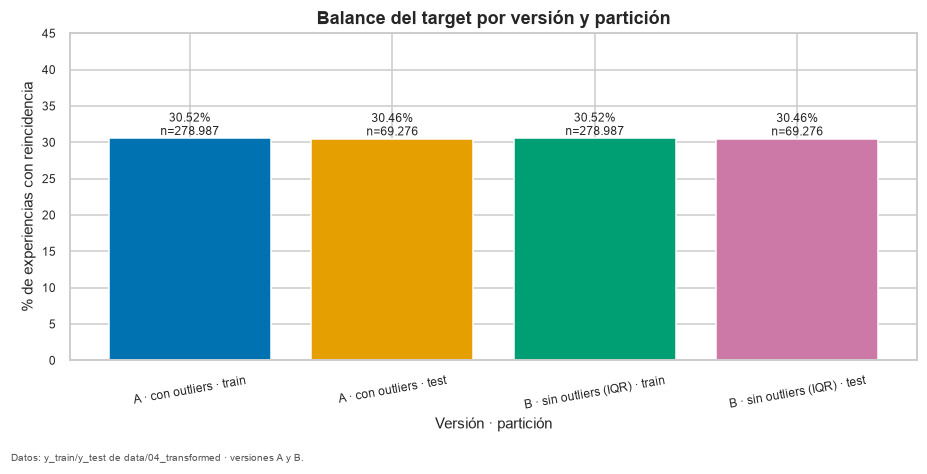

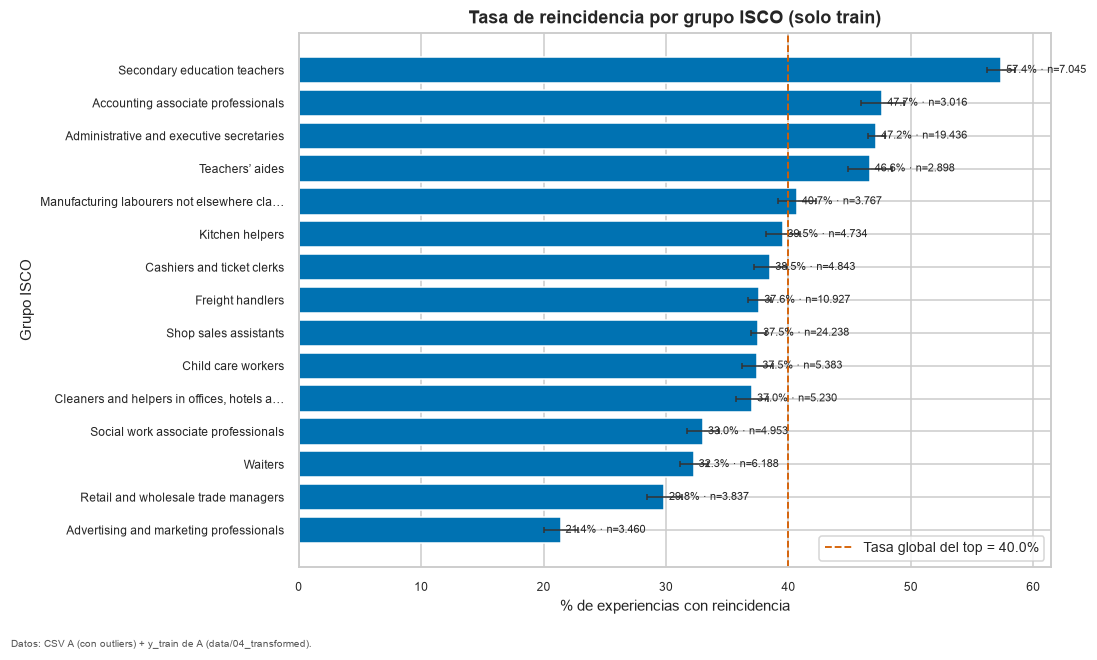

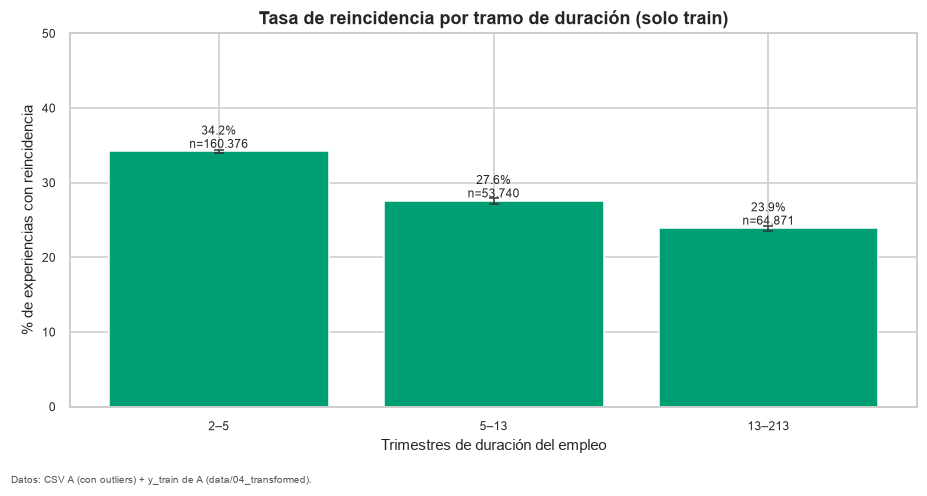

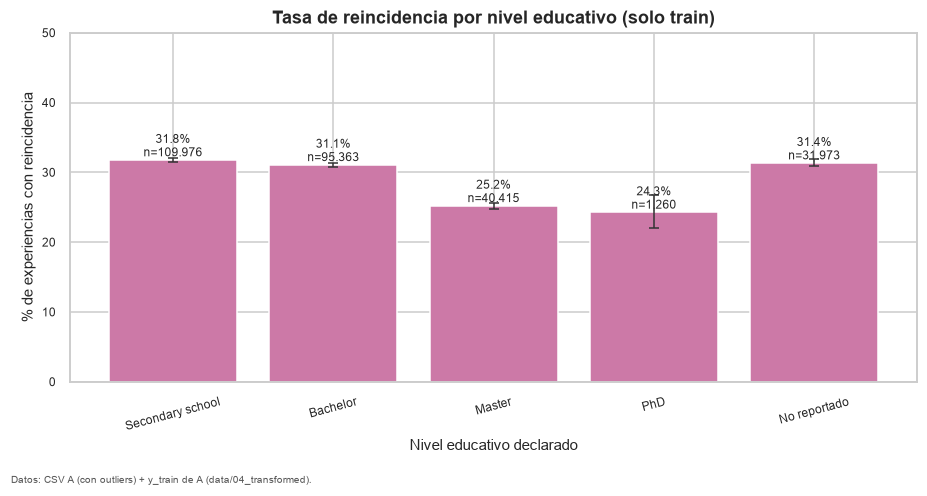

In [19]:
figures = pipeline.render_target()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** G26 confirma que train y test tienen la misma prevalencia y que A/B no se separan. G27 ordena los grupos ISCO por tasa: la horquilla es amplia y los intervalos no se solapan en varios pares, lo que sugiere una asociación real. G28 muestra un gradiente descendente: a mayor duración, menor tasa de reincidencia. G29 muestra diferencias más pequeñas y un grupo "No reportado" que no se puede interpretar como un nivel educativo real.

La advertencia de "qué estudió" sigue vigente: G29 compara niveles, no programas. Un máster en un campo saturado y un máster en un campo con demanda pueden tener trayectorias distintas, y la fuente no permite separarlos.

## 11. Auditoría de fuga y circularidad

**¿Qué hace?** Comprueba si las columnas de repetición reproducen el target fila a fila, si `n_returns` equivale a la repetición a nivel persona y qué columnas de `X` delatan el target por su nombre. Además, tabula la tasa de target según el número de veces que la persona tuvo ese oficio.

**¿Por qué existe?** Es la condición más importante del encargo: el target no puede estar dentro de las features. La auditoría convierte esa sospecha en evidencia ejecutada y deja una lista de columnas a excluir.

**¿Qué recibe y qué entrega?** Recibe train, la tabla por persona y las columnas de fuga de `X`. Entrega la tabla de auditoría, la contingencia y la lista de columnas prohibidas.

**Papel en el proyecto.** Es un riesgo bloqueante para la fase 4 y una decisión obligatoria del informe.

In [20]:
pipeline.leakage_analysis()

display(
    pipeline.results.leakage_audit.rename(
        columns={
            "variable": "variable",
            "check": "control",
            "value": "valor",
            "verdict": "veredicto",
            "detail": "detalle",
        }
    )
)
display(
    pipeline.results.leakage_contamination.rename(
        columns={
            "veces_mostrada": "veces_en_el_oficio",
            "n": "experiencias",
            "positivos": "positivos",
            "tasa_pct": "tasa_pct",
        }
    )
)
print("Columnas de X que delatan el target:", pipeline.results.x_leak_columns)

,variable,control,valor,veredicto,detalle
0,veces_ese_oficio,veces_ese_oficio > 1 == target,100.000,FUGA DIRECTA,La columna original define el target fila a fila.
1,veces_ese_oficio_bin,bin > 0 == target,100.000,FUGA DIRECTA,La versión discretizada conserva la definición del target.
2,veces_ese_oficio_rob,rob > 0 == target,100.000,FUGA DIRECTA,La versión robusta escalada también conserva el signo.
3,veces_ese_oficio_rob,correlación con el target,0.737,FUGA DIRECTA,Correlación alta esperada por construcción.
4,n_returns,(n_returns >= 1) == any_repeated,100.000,CIRCULARIDAD,"A nivel persona, tener al menos un retorno equivale a tener al menos un empl..."


,veces_en_el_oficio,experiencias,positivos,tasa_pct
0,1,193840,0,0.000
1,2,49112,49112,100.000
2,3,19029,19029,100.000
3,4,8312,8312,100.000
4,5,8694,8694,100.000


Columnas de X que delatan el target: ['veces_ese_oficio_rob', 'veces_ese_oficio_bin']


**Lectura.** La auditoría no deja lugar a dudas: las tres formas de `veces_ese_oficio` reproducen el target en todas las filas de train, y `n_returns` equivale a la repetición a nivel persona. La contingencia lo hace todavía más claro: con una sola vez en el oficio la tasa es cero; con dos o más, es cien. No es una asociación estadística, es la definición.

La consecuencia es obligatoria: `veces_ese_oficio`, `veces_ese_oficio_bin` y `veces_ese_oficio_rob` se excluyen de `X` antes de la fase 4. `n_returns` y `n_nonadjacent_returns` no se cruzan con el target. Si un modelo se entrenara con estas columnas, obtendría una métrica perfecta y completamente inútil.

**Figura G30 · panel de fuga**

**¿Qué hace?** Panel izquierdo: porcentaje de filas en que cada variable reproduce el target. Panel derecho: tasa de target según veces en el oficio.

**¿Por qué existe?** Es la evidencia visual de la fuga; la tabla es el detalle numérico.

**¿Qué recibe y qué entrega?** Recibe la auditoría y la contingencia. Entrega un PNG.

**Fuente de datos.** G30 usa `X_train.csv` y `y_train.csv` de A (`data/04_transformed`).

**Papel en el proyecto.** Queda como advertencia visual para cualquiera que revise la fase 4.


Figuras generadas: G30


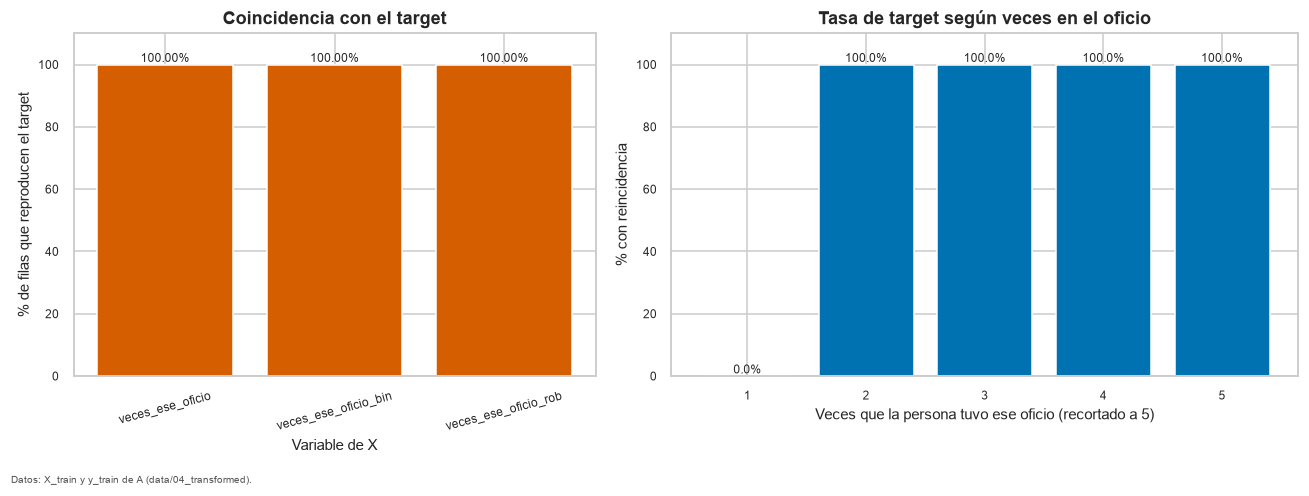

In [21]:
figures = pipeline.render_leakage()
print("Figuras generadas:", ", ".join(sorted(figures)))
plt.show()
plt.close("all")

**Lectura.** El panel izquierdo muestra barras al cien por cien para las tres variantes de repetición. El panel derecho muestra el escalón entre una y dos veces: la etiqueta no captura un gradiente, captura un umbral. La figura no se usa para elegir un punto de corte; se usa para prohibir esas columnas.

## 12. Segmento derivado de trayectoria

**¿Qué hace?** Calcula los umbrales Q75 de autolazo, exploración y retorno no adyacente sobre personas con al menos dos empleos; asigna cuatro tipos (permanente, exploradora, mixta, sin transición); y valida el segmento contra nivel educativo e ISCO con V de Cramér.

**¿Por qué existe?** El charter pide patrones de trayectoria, y una sola variable binaria no los resume. El segmento es una descripción tipológica construida con umbrales observados, no inventados.

**¿Qué recibe y qué entrega?** Recibe la tabla por persona. Entrega umbrales, conteos por segmento, perfil medio y tablas de validación contra educación e ISCO.

**Papel en el proyecto.** Alimenta la sección de perfiles del informe. **No se cruza con `reincide`**: el retorno comparte definición con el target y la comparación sería circular.

In [22]:
display(pd.DataFrame([pipeline.results.thresholds]).T.rename(columns={0: "valor"}))
display(pipeline.results.segment_summary)
display(pipeline.results.segment_by_education)
display(pipeline.results.segment_by_isco)
display(pd.DataFrame([pipeline.results.segment_cramers_v]).T.rename(columns={0: "V_de_Cramer"}))

,valor
self_loop_q75,0.200
exploration_q75,1.000
nonadjacent_q75,0.125
n_persons,"66,384.000"


,segmento,personas,empleos_medios,oficios_medios,retornos_medios,autolazo_medio,pct
0,permanente,16877,5.882,3.351,2.150,0.441,23.970
1,exploradora,25091,3.976,3.976,0.000,0.000,35.640
2,mixta,24416,7.054,5.107,1.105,0.030,34.680
3,sin transición,4013,1.000,1.000,0.000,0.000,5.700


university_level,segmento,Bachelor,Master,No reportado,PhD,Secondary school
0,exploradora,31.130,16.420,12.250,0.550,39.660
1,mixta,34.470,14.750,11.090,0.540,39.150
2,permanente,32.420,11.260,12.720,0.330,43.280
3,sin transición,24.300,13.850,15.200,1.020,45.630


isco_main,segmento,Administrative and executive secretaries,Cashiers and ticket clerks,Child care workers,"Cleaners and helpers in offices, hotels and other establishments",Freight handlers,Kitchen helpers,Secondary education teachers,Shop sales assistants,Social work associate professionals,Waiters
0,exploradora,17.820,5.910,4.830,4.650,12.140,4.720,4.120,33.110,4.660,8.030
1,mixta,21.350,4.690,5.910,4.600,12.940,4.180,6.670,27.450,5.670,6.530
2,permanente,26.220,4.400,4.440,5.640,10.010,5.810,8.670,26.190,3.860,4.760
3,sin transición,20.220,6.870,4.640,8.550,12.790,8.550,5.680,24.220,2.640,5.840


,V_de_Cramer
segmento_vs_nivel_educativo,0.048
segmento_vs_isco,0.088


**Lectura.** Los cuatro tipos tienen perfiles distintos. El permanente acumula más empleos y más autolazos; el explorador tiene muchos oficios distintos y ningún retorno; el mixto combina volumen alto con retorno moderado; el sin transición es el grupo de una sola experiencia. La validación contra educación e ISCO muestra asociaciones débiles: el segmento no está determinado por el nivel educativo ni por el área, lo que lo hace una descripción de forma de trayectoria y no un reflejo de esas variables.

La V de Cramér se usa solo como tamaño de asociación descriptivo. No hay prueba de hipótesis ni comparación con el target. Si en la fase 4 se quiere usar el segmento como feature, habrá que construirlo dentro del pipeline de entrenamiento y verificar que no filtre información del target.

## 13. Hallazgos y bitácora de decisiones

**¿Qué hace?** Construye la bitácora con el formato exigido: hallazgo, evidencia, figura, acción y tarea CRISP-DM. Cada evidencia se arma con valores producidos por las celdas anteriores.

**¿Por qué existe?** La rúbrica pide al menos tres hallazgos con evidencia y acción, y una tabla de decisiones trazable. Este bloque los reúne y los deja listos para el informe.

**¿Qué recibe y qué entrega?** Recibe los resultados del pipeline. Entrega un DataFrame de decisiones.

**Papel en el proyecto.** Es el puente entre el EDA y la fase 4: cada acción dice qué hacer con lo encontrado.

In [23]:
decisions = pipeline.record_findings()
with pd.option_context("display.max_colwidth", 240, "display.width", 240):
    display(decisions)
print("Número de hallazgos registrados:", len(decisions))


,hallazgo,evidencia,figura,accion,tarea_crispdm
0,El target está dentro de la matriz de features,veces_ese_oficio_bin reproduce el target en el 100.00% de las filas de train; la columna también existe como veces_ese_oficio_rob y veces_ese_oficio.,G30,"Excluir veces_ese_oficio, veces_ese_oficio_bin y veces_ese_oficio_rob de X antes de la fase 4; registrar la fuga como riesgo bloqueante.",Data Understanding · verificación de calidad
1,La duración se concentra en valores redondos,El valor 2 trimestres aparece en 113.126 experiencias (30.04%).,G01,Mantener dur_q como medida descriptiva; no derivar de los picos una regla de negocio sin validar con la fuente.,Data Understanding · describir
2,La repetición de oficio es frecuente a nivel persona,45.59% de las personas tiene al menos un retorno a un oficio previo; el autolazo representa 12.57% de las transiciones.,G13,Usar n_returns solo como descriptor; no cruzarlo con el target porque es una reexpresión del mismo fenómeno.,Data Understanding · explorar
3,El cambio lateral dentro del área pesa más que el autolazo,El autolazo es el 12.57% de las transiciones y la permanencia en el mismo grupo ISCO llega al 17.43%; en secondary school teacher el 39.55% de las salidas se queda en el mismo grupo ISCO.,G22,En fase 4 tratar occupation_code e isco_group como bloques separados y no leer un cambio de ISCO como promoción.,Data Understanding · explorar relaciones
4,La cobertura del emparejamiento ESCO es estable en el tiempo,Entre 2000 y 2020 la proporción de experiencias emparejadas se mantiene entre 89.37% (2020) y 93.96% (2000); el oficio no clasificado no es un deterioro reciente de la fuente.,G10,Tratar el oficio no clasificado como nulo estructural y no imputarlo; en fase 4 evaluar un indicador explícito de missing de oficio.,Data Understanding · verificar calidad
5,El target está moderadamente desbalanceado,"Prevalencia en train = 30.52% (IC 95 %: 30.35–30.69), con 85.147 positivos de 278.987 filas.",G26,"En fase 4, usar métricas sensibles al desbalance (PR-AUC, recall) y no solo exactitud.",Data Understanding · describir el target
6,La duración del empleo se asocia con la reincidencia,La tasa va de 23.91% a 34.19% entre tramos de duración; la diferencia es de 10.28 puntos.,G28,"Mantener dur_q y sus derivados en la fase 4, controlando la colinealidad con dur_total y span_q.",Data Understanding · explorar relaciones
7,El diagnóstico PCA es estable entre muestras,PC1 explica entre 32.21% y 32.43% y se necesitan 4 componentes para el 80% en la versión con outliers.,G23,No repetir el PCA en el EDA; reutilizar el diagnóstico de 4.0/4.1 como evidencia de estabilidad.,Data Understanding · verificar calidad
8,El segmento de trayectoria requiere umbrales observados,"Q75 de autolazo = 0.2000, Q75 de exploración = 1.0000, Q75 de retorno no adyacente = 0.1250 sobre 66.384 personas con al menos dos empleos.",Tabla de segmentos,Usar el segmento solo para describir perfiles; no compararlo con el target porque comparte la definición de retorno.,Data Understanding · explorar


Número de hallazgos registrados: 9


**Lectura.** La bitácora cubre los frentes que el encargo pedía: fuga del target, picos de duración, frecuencia de retorno, desbalance, asociación con duración, estabilidad del PCA y necesidad de umbrales observados para el segmento. Cada fila tiene una acción concreta; ninguna se queda en la descripción.

Las acciones más urgentes para la fase 4 son dos: excluir las columnas de repetición de `X` y elegir métricas sensibles al desbalance. Las demás son recomendaciones de interpretación y de control de colinealidad.

## 14. Validación final de reproducibilidad

**¿Qué hace?** Compara la huella SHA-256 de cada insumo con la tomada al inicio, verifica que las 28 figuras aprobadas existen y comprueba que ningún cruce con el target usó una partición distinta de train.

**¿Por qué existe?** Es el cierre que exige la rúbrica: el EDA no puede modificar los datos y no puede mirar el test para elegir features. La validación lo demuestra, no lo promete.

**¿Qué recibe y qué entrega?** Recibe la huella inicial, el manifiesto de figuras y el registro del guardián. Entrega tres tablas de control.

**Papel en el proyecto.** Es la garantía de que el cuaderno se puede volver a ejecutar y de que la fase 4 parte de insumos intactos.


In [24]:
pipeline.validate()

display(
    pipeline.results.input_integrity.rename(
        columns={
            "archivo": "archivo",
            "ruta": "ruta",
            "sha256_antes": "sha256_antes",
            "sha256_despues": "sha256_despues",
            "sin_cambios": "sin_cambios",
        }
    )
)
display(pipeline.results.figure_manifest)
display(pipeline.results.target_usage)
print("Todos los insumos intactos:", bool(pipeline.results.input_integrity["sin_cambios"].all()))
print("Todas las figuras presentes:", bool(pipeline.results.figure_manifest["existe"].all()))
print("Todos los cruces con target en train:", bool(pipeline.results.target_usage["solo_train"].all()))

,archivo,ruta,sha256_antes,sha256_despues,sin_cambios
0,empleos_limpio_con_competencias.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_lim...,0a79e7bb245b13ec…,0a79e7bb245b13ec…,True
1,empleos_limpio_con_competencias_sin_outliers.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\03_processed\empleos_lim...,6a9d62f7f0e7ef89…,6a9d62f7f0e7ef89…,True
2,X_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\con_outli...,2e27c0b882216941…,2e27c0b882216941…,True
3,y_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\con_outli...,edba8ea4d5e9990e…,edba8ea4d5e9990e…,True
4,X_test.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\con_outli...,830ae22e7e7e3d19…,830ae22e7e7e3d19…,True
5,y_test.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\con_outli...,c16f27758a841eb3…,c16f27758a841eb3…,True
6,transformers.joblib,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\transform...,5c61337d836db236…,5c61337d836db236…,True
7,X_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\sin_outli...,1da3f13764a31715…,1da3f13764a31715…,True
8,y_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\sin_outli...,edba8ea4d5e9990e…,edba8ea4d5e9990e…,True
9,X_test.csv,C:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\sin_outli...,0980976712f58276…,0980976712f58276…,True


,figura,existe,tamano_kb
0,g01_duracion_empleo_hist.png,True,37.000
1,g02_top_ocupaciones.png,True,65.600
2,g03_duracion_por_isco.png,True,71.600
3,g04_nivel_educativo.png,True,37.400
4,g05_competencias_esenciales_hist.png,True,34.400
5,g06_competencias_por_isco.png,True,80.600
6,g07_experiencias_por_anio.png,True,46.600
7,g08_nulos_por_columna.png,True,68.500
8,g09_outliers_iqr_ab.png,True,37.600
9,g10_cobertura_esco_por_anio.png,True,48.900


,analysis,split,solo_train
0,balance del target,train,True
1,tasa global del target,train,True
2,tasa por ISCO,train,True
3,cortes de dur_q,train,True
4,tasa por duración,train,True
5,tasa por nivel educativo,train,True


Todos los insumos intactos: True
Todas las figuras presentes: True
Todos los cruces con target en train: True


**Lectura.** Si las tres columnas de control dicen verdadero, el cuaderno cumple las reglas duras: insumos intactos, figuras completas y target solo en train. Cualquier falso sería un error bloqueante, no una advertencia.

La validación no comprueba la calidad del análisis, solo su reproducibilidad y sus límites. La interpretación sigue siendo responsabilidad humana.

## 15. Cierre, límites y siguiente fase

### 15.1 Lo que el EDA respondió

- Describió la duración, el oficio, la formación declarada y las competencias del universo.
- Amplió la mirada descriptiva con duración por área, perfil de competencias por ISCO, cobertura ESCO, duración de la trayectoria, forma del segmento, movimientos frecuentes y tasas por ocupación de origen.
- Midió el volumen de empleos y la movilidad por persona.
- Construyó el mapa de transiciones finas y agregadas.
- Auditó la fuga del target y la circularidad de `n_returns`.
- Comparó A y B y evaluó el what-if de `dur_q`.
- Reutilizó el PCA de 10 k y 50 k como evidencia de estabilidad.
- Propuso un segmento de trayectoria con umbrales observados, sin mirar el target.

### 15.2 Límites declarados

1. **"Qué estudió" no está en la fuente.** `university_level`, `isco_group` y el perfil de competencias son proxies parciales; no son el programa ni el campo de estudio.
2. **El target no es el charter completo.** `reincide` etiqueta repetición de oficio, no dirección ni calidad de la transición.
3. **El PCA reutilizado no cubre `X`.** Cubre las variables numéricas escaladas del bloque de transformación; no se hizo un PCA sobre las 2.839 columnas.
4. **La duración no se winsoriza.** El what-if es un diagnóstico, no una transformación aplicada.
5. **El segmento es descriptivo.** No se cruzó con el target y no debe interpretarse como predictor validado.
6. **Los nulos de oficio son estructurales.** No se imputaron y no se deben tratar como missing aleatorio.

### 15.3 Persistencia del nombre del target

El nombre `is_repeated_occupation` se creó solo en RAM. Para persistirlo habría que:

1. editar la línea de `src/transformacion/transformacion.py` donde se exporta `reincide`;
2. volver a ejecutar `notebooks/refactor/3.0_transformacion.ipynb`;
3. actualizar las referencias en los cuadernos y en la documentación.

Ese cambio **no se hizo aquí** porque el EDA no debe reescribir la fase 3.

### 15.4 Lo que la fase 4 debe hacer

- Excluir `veces_ese_oficio`, `veces_ese_oficio_bin` y `veces_ese_oficio_rob` de `X`.
- No usar `n_returns` ni `n_nonadjacent_returns` como features.
- Elegir métricas sensibles al desbalance (PR-AUC, recall, F1 de la clase positiva).
- Controlar la colinealidad de duración y competencias.
- Validar cualquier uso del segmento dentro del pipeline de entrenamiento.
- Documentar si se decide volver al 2.0 por `dur_q` o por los nulos estructurales.

### 15.5 Checklist de entrega

- [x] Cuaderno único ejecutado de punta a punta.
- [x] Lógica pesada en `scripts/ScriptsCsv/EDA/`, importada por el cuaderno.
- [x] 28 figuras aprobadas en `reports/eda_jobpath/figures/`.
- [x] Tabla G24 de cargas del PCA mostrada en el cuaderno.
- [x] Mapa `resume_id → split` en `reports/eda_jobpath/tables/`.
- [x] Bitácora de decisiones con hallazgo, evidencia, figura, acción y tarea CRISP-DM.
- [x] Insumos con huella SHA-256 sin cambios.
- [x] Target cruzado solo en train.
- [x] Límites de "qué estudió", PCA y segmento declarados.
